# Tutorial 3 · Two 17-qubit surface-code chips from one generator

Two chips with the same topology, rebuilt in the Quantcore PDK:

1. **DeviceLayout.jl DemoQPU17** (© Amazon.com, Inc., MIT licence, <https://github.com/aws-cqc/DeviceLayout.jl>,
   `examples/DemoQPU17`): a demo after the ETH device; 15 × 15 mm, 1.65 mm lattice pitch, 48 ports. Design notebook
   `examples/designs/devicelayout/demoqpu17.ipynb`, spec `docs/designs/devicelayout/demoqpu17.md`.
2. **The ETH Zurich 17-qubit device** — S. Krinner *et al.*, "Realizing repeated quantum error correction in a
   distance-three surface code", Nature 605, 669 (2022), arXiv:2112.03708 (Table I and Methods give the targets);
   layout mock-up in Quantum Metal notebook 53 (Apache-2.0). Design notebook
   `examples/designs/metal/m53_wallraff_17q.ipynb`, spec `docs/designs/metal/53_wallraff_17q.md`.

Both are laid out by one generator, `examples/designs/devicelayout/_surface17.py`: the source fixes the lattice, the
port map, the feedline groups and the targets; the geometry is drawn with our components and routes.

**The chip, in four ideas.**

- **The lattice.** 17 transmons on the 5 × 5 sites `01100 / 01111 / 11111 / 11110 / 00110`: 9 *data* qubits and 8
  *auxiliary* (measure) qubits in a checkerboard (data where row + column is even), and 24 nearest-neighbour CPW
  couplers. Each auxiliary qubit measures the parity of its 2–4 data neighbours: X- or Z-type stabilisers of the
  distance-3 surface code.
- **Readout with Purcell filters.** Each qubit has a λ/4 readout resonator coupled (a tap capacitor) to its own λ/4
  Purcell filter, resonant with it. Only the filter touches the feedline (through a capacitive tee), so the qubit
  decays slowly into the line while the readout stays fast. Four feedlines read 4–5 qubits each, every line with a
  series input capacitor.
- **Control lines.** An XY (drive) and a Z (flux) line per qubit: 34 lines from the pads into the lattice.
- **Crossings → airbridges.** With 4 feedlines and 34 control lines fanning in, lines must cross. The generator finds
  every crossing on the drawn polylines; the higher-ranked line (couplers < resonators < feedlines < Z < XY) is split
  there and an `AirbridgeConnection` carries it over the lower one (DeviceLayout's `crossovers!`).

| | DemoQPU17 | ETH 17q | the PDK changes |
|---|---|---|---|
| qubits | DeviceLayout's star transmon | ETH's 6-arm transmons | Quantum Metal `StarQubit` (5 pads) with a **trilayer SQUID** |
| targets | readouts 6.8–7.6 GHz; no f_q given (plan: data 4.8–5.2, aux 5.8–6.15 GHz) | Table I: data 3.74–4.14, aux 5.89–6.33 GHz; readouts 6.77–7.55 GHz | f_q outside 4–8 GHz and R_n outside 40–50 kΩ are flagged |
| pads | 200 µm in from the edge | 200 µm in | **100 µm** from the edge (`edge="auto"`) |
| cheese | holes not drawn | flux-trap holes not drawn | the PDK band |

Runtime ≈ 3–5 min (two 17-qubit builds of ≈ 20 s each, 34 per-qubit LOM groups).

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

**Dashboard** (`track.start("t03")` in the setup cell): every build, DRC, LOM run, FEM job (with its pass / Δ / mesh while AEDT runs) and feedback step is recorded into `build/t03/state.json`; `scripts\dashboard.cmd` in a terminal shows it live at http://127.0.0.1:8765/ (`track.stop()` switches the recording off).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "examples" / "tutorials"))
import _tut as T
T.setup("t03")                                    # also puts examples/designs/devicelayout on sys.path
import _common as C
import _surface17 as S17                          # the surface-17 generator
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

KLAYOUT_GUI = True                                # True: open / raise the KLayout window; False: redraw an open one only
LIVE = T.live_mode(gui=KLAYOUT_GUI)
from quantcore_circuits import track
TRACKING = track.start("t03")                     # dashboard (scripts\dashboard.cmd) follows build/t03
pdk = get_pdk()

Headless (QCC_LIVE=0): each build writes build/<name>.oas; pictures are headless KLayout snapshots.


### The FEM part in two stages, and its switches

Every tutorial runs its FEM part in two stages (section A11 here):

1. **Subset check (FEM only).** `SIM_SUBSET` lists `(qubit, readout)` pairs (`None` = the qubit's own readout chain:
   its readout hairpin, the declared readout–Purcell tap, the Purcell hairpin and its tee on the feedline).
   `Designer.sim_subset` cuts one box per pair: the feedline through the tee is always in the box and is cut into 50 Ω
   ports; the couplers to neighbouring qubits outside the subset are cut at the chosen qubit (Q3D: each coupler pad is
   its own net); a coupler between two chosen qubits comes in. You look at FEM values only — convergence, the raw
   C-matrix, the FEM-filled capacitances next to their estimates — and, if they are sane and converged, go on. No LOM
   is simulated on a subset and nothing is fed back from it.
2. **The whole LOM.** The subset values are filled into the **whole** 17-qubit netlist (every other branch keeps its
   estimate, `scope="auto"`), and the LOM runs on that whole netlist (per qubit group, as in A9). Today the
   StarQubit pin guard keeps Q23's estimates too, so the LOM values are the component estimates (the notebook says
   so). `FEM_WHOLE = True` (opt-in) renders the whole chip into AEDT (no solve: 17 qubits need a server).

**What runs here:** the Q3D C-matrix of the subset (≈ 1 min for one qubit). The eigenmode / EPR groups
(A11) are exported, not solved here. All their ports have a polygon: the StarQubit junction port spans the gap on
the junction axis, and a line that leaves the box at 45° gets its 50 Ω port on its own axis. `RESOLVE`
re-solves jobs whose kept results match (after a library fix, say).

In [2]:
SIM_SUBSET = [("Q23", None)]     # stage 1: (qubit, readout) pairs; None = its readout chain; e.g. [("Q23", None), ("Q33", None)]
SUBSET_ANALYSES = ["q3d_cmatrix"]  # Q3D only here; the eigenmode groups are exported in A11
RUN_FEM = False                  # True: solve the SIM_SUBSET jobs, render Q23_Q33 and the whole chip in AEDT, one at a time
FEM_WHOLE = False                # True (opt-in): render the whole chip into AEDT (no solve: a server job)
RESOLVE = False                  # True (or a set of analyses): re-solve even when the kept results match
FEM_FAST = True                  # True: fast test settings (few passes, values not converged); False: converged settings
AEDT_MODE = "batch"              # "batch" (no window) | "gui" (a new AEDT window) | "attach" (yours)

# Part A · DeviceLayout DemoQPU17, step by step

## A1 · The lattice

`S17.SITES` are the 17 active sites (row, column), row 1 at the top. Labels follow DeviceLayout: `Q<row><col>`.
`S17.neighbours` lists the 24 couplers.

In [3]:
LABELS = {s: f"Q{s[0]}{s[1]}" for s in S17.SITES}
grid = [[" ··· "] * 5 for _ in range(5)]
for (r, c), name in LABELS.items():
    grid[r - 1][c - 1] = f"{name}{'d' if S17.is_data((r, c)) else 'a'}"
print("\n".join(" ".join(row) for row in grid), "\n(d = data, a = auxiliary)")
CPLS = S17.neighbours(LABELS)
print(len(CPLS), "couplers, e.g.", CPLS[:4])

 ···  Q12a Q13d  ···   ··· 
 ···  Q22d Q23a Q24d Q25a
Q31d Q32a Q33d Q34a Q35d
Q41a Q42d Q43a Q44d  ··· 
 ···   ···  Q53d Q54a  ···  
(d = data, a = auxiliary)
24 couplers, e.g. [('CPL_Q12_Q13', 'Q12', 'Q13'), ('CPL_Q12_Q22', 'Q12', 'Q22'), ('CPL_Q13_Q23', 'Q13', 'Q23'), ('CPL_Q22_Q23', 'Q22', 'Q23')]


## A2 · What the source fixes: ports, readout targets, feedline groups, mirroring

DeviceLayout numbers the 48 ports clockwise from the top-left at 1 mm pitch; `PORTS` maps each used one to its line
(42 of 48). Each quadrant's readout modules are mirrored away from the lattice centre (`MIRRORED_LR` / `_UD`), so
every readout diagonal and control line points outwards. The readout targets and the four feedline groups are
DeviceLayout's `params.jl`. DeviceLayout gives no qubit frequencies; the plan puts data qubits at 4.80–5.20 GHz and
auxiliary qubits at 5.80–6.15 GHz.

In [4]:
W = H = 15000.0                                   # ExampleChip 15 × 15 mm; Designer frame = DeviceLayout + (7.5, 7.5) mm
EDGE = 900.0                                      # source: pad port 900 µm in (pad etch edge 200 µm from the die edge)


def dl_pad(i):
    """DeviceLayout ExampleChip port i (1–48, clockwise from the top-left, 1 mm pitch): (x, y, port direction)."""
    if i <= 12:
        return (2000 + 1000 * (i - 1), H - EDGE, 270.0)
    if i <= 24:
        return (W - EDGE, 13000 - 1000 * (i - 13), 180.0)
    if i <= 36:
        return (13000 - 1000 * (i - 25), EDGE, 90.0)
    return (EDGE, 2000 + 1000 * (i - 37), 0.0)


def quadrant(r, c):                               # params.jl MIRRORED_LR / MIRRORED_UD
    lr, ud = c > 3 or (c == 3 and r < 3), r > 3 or (r == 3 and c > 3)
    return {(False, False): "NW", (True, False): "NE", (True, True): "SE", (False, True): "SW"}[(lr, ud)]


QUAD = {q: quadrant(*s) for s, q in LABELS.items()}
F_RO = {"Q12": 7.0, "Q13": 7.3, "Q22": 7.4, "Q23": 7.1, "Q24": 7.5, "Q25": 6.9, "Q31": 7.2, "Q32": 7.6, "Q33": 6.8,
        "Q34": 7.6, "Q35": 7.4, "Q41": 6.9, "Q42": 7.3, "Q43": 7.5, "Q44": 7.2, "Q53": 7.1, "Q54": 7.0}
DATA = [q for s, q in LABELS.items() if S17.is_data(s)]
AUX = [q for q in LABELS.values() if q not in DATA]
F_Q = {q: round(4.80 + 0.05 * DATA.index(q), 3) if q in DATA else round(5.80 + 0.05 * AUX.index(q), 3)
       for q in LABELS.values()}
PORTS = {1: "Z_Q22", 2: "XY_Q12", 4: "Z_Q12", 5: "Z_Q33", 7: "Z_Q13", 9: "XY_Q13", 10: "Z_Q23", 11: "XY_Q23",
         12: "Z_Q24", 13: "XY_Q24", 14: "Z_Q25", 16: "XY_Q25", 19: "XY_Q35", 21: "Z_Q35", 22: "XY_Q34", 23: "Z_Q34",
         24: "XY_Q44", 25: "Z_Q44", 26: "XY_Q54", 28: "Z_Q54", 31: "Z_Q53", 33: "XY_Q53", 34: "Z_Q43",
         35: "XY_Q43", 36: "Z_Q42", 37: "XY_Q42", 38: "Z_Q41", 40: "XY_Q41", 42: "XY_Q33", 43: "XY_Q31",
         45: "Z_Q31", 46: "XY_Q32", 47: "Z_Q32", 48: "XY_Q22"}               # LINE_SPECIFICATIONS
FEEDS = {1: (44, 3, ["Q31", "Q32", "Q33", "Q22", "Q12"]), 2: (15, 8, ["Q25", "Q24", "Q23", "Q13"]),
         3: (20, 27, ["Q35", "Q34", "Q44", "Q54"]), 4: (39, 32, ["Q41", "Q42", "Q43", "Q53"])}  # RO_IN → RO_OUT
PADS = {f"L{i}": dl_pad(i) for i in sorted(set(PORTS) | {p for a, b, _ in FEEDS.values() for p in (a, b)})}
T.md("| feedline | in → out port | qubits (in order) |\n|---|---|---|\n" + "\n".join(
    f"| {k} | {a} → {b} | {', '.join(qs)} |" for k, (a, b, qs) in FEEDS.items()))

| feedline | in → out port | qubits (in order) |
|---|---|---|
| 1 | 44 → 3 | Q31, Q32, Q33, Q22, Q12 |
| 2 | 15 → 8 | Q25, Q24, Q23, Q13 |
| 3 | 20 → 27 | Q35, Q34, Q44, Q54 |
| 4 | 39 → 32 | Q41, Q42, Q43, Q53 |

## A3 · The floorplan and the plan

`S17.Config` holds what the source fixes plus our floorplan choices. The centre qubit Q33 sits in a *closed
plaquette* (all four neighbours around it), so its readout hairpin is shortened and its tee and Purcell filter sit in
the channel west of the plaquette, with the filter lead bridged over a coupler; its two control lines come in through
vias. Readout and Purcell lengths are v_ph/4f on the PDK stack times a loading factor (0.96 / 0.948, calibrated once
with the LOM: the qubit and the tee pull the resonance down).

`S17.plan_chip(cfg)` lays everything out on paper: instances, the polylines of every line, the crossings and the
airbridges, and a list of crossings it could not bridge cleanly (none here).

In [5]:
FEEDLINES = {k: dict(pad_in=f"L{a}", pad_out=f"L{b}", qubits=qs) for k, (a, b, qs) in FEEDS.items()}
FEEDLINES[1].update(r=40.0, stubs={"Q32": (520.0, 410.0), "Q33": (90.0, 90.0), "Q22": (472.0, 520.0)})
CONTROLS = {line: dict(pad=f"L{i}") for i, line in PORTS.items()}
SHORT = {"Q33": dict(ro_legs=5, tee=(5550.0, 8790.0), tee_rot=45.0, pf_u0=1479.5, pf_u_far=1600.0)}
CONTROLS["XY_Q33"].update(vias=[(6450.0, 7000.0)], u_out=1000.0, dv=-160.0)
CONTROLS["Z_Q33"].update(vias=[(6650.0, 11400.0)], u_out=1600.0)
CFG = S17.Config(name="t03_demoqpu17", box=(W, H), centre=(7500.0, 7500.0), pitch=(1650.0, 1650.0), labels=LABELS,
                 quadrant=QUAD, f_ro=F_RO, f_q=F_Q, pads=PADS, feedlines=FEEDLINES, controls=CONTROLS,
                 shortened=SHORT, length_scale=0.96, pf_length_scale=0.948)
PLAN = S17.plan_chip(CFG)
print(S17.summary(PLAN))
print("plan problems:", PLAN["problems"] or "none")

{'instances': {'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4, 'BondPad': 42, 'AirbridgeConnection': 37}, 'lines': {'coupler': 24, 'resonator': 34, 'feed': 25, 'z': 17, 'xy': 17}, 'routes': 154, 'airbridges': 37, 'problems': 0}
plan problems: none


## A4 · Junctions: trilayer SQUIDs sized for the plan

Every qubit is a flux-tunable `Quantcore Squid` (two trilayer junctions in parallel), sized with
`circuit.bridges.size_junction(f_q, C_Σ, n=2)` on the StarQubit's effective C_Σ ≈ 89 fF (from the LOM). The PDK
window (40–50 kΩ) judges the device: the SQUID's parallel R_n, half of each junction's. Qubits outside it are flagged
by the DRC (`pdk_rn`), not retuned.

In [6]:
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.registry import trilayer_junction

C_SIGMA = 89.0
SIZING = {q: size_junction(F_Q[q], C_SIGMA, n=2) for q in LABELS.values()}
JJ = {q: trilayer_junction("metal:StarQubit", lj_nH=s.lj_nH, squid=True) for q, s in SIZING.items()}
T.md("| qubit | role | f_q plan (GHz) | L_J total (nH) | R_n per junction (kΩ) | device R_n (kΩ) | in 40–50 kΩ |\n"
     "|---|---|---|---|---|---|---|\n"
     + "\n".join(f"| {q} | {'data' if q in DATA else 'aux'} | {s.f_q_GHz:.3f} | {s.lj_nH:.2f} | "
                 f"{s.drawn.rn_each_kohm:.1f} | {s.drawn.rn_kohm:.1f} | {'yes' if s.drawn.rn_in_window else 'no'} |"
                 for q, s in SIZING.items()))

| qubit | role | f_q plan (GHz) | L_J total (nH) | R_n per junction (kΩ) | device R_n (kΩ) | in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q12 | aux | 5.800 | 7.86 | 107.1 | 53.6 | no |
| Q13 | data | 4.800 | 11.30 | 150.0 | 75.0 | no |
| Q22 | data | 4.850 | 11.08 | 150.0 | 75.0 | no |
| Q23 | aux | 5.850 | 7.73 | 102.3 | 51.1 | no |
| Q24 | data | 4.900 | 10.87 | 150.0 | 75.0 | no |
| Q25 | aux | 5.900 | 7.60 | 102.3 | 51.1 | no |
| Q31 | data | 4.950 | 10.66 | 140.6 | 70.3 | no |
| Q32 | aux | 5.950 | 7.48 | 97.8 | 48.9 | yes |
| Q33 | data | 5.000 | 10.45 | 140.6 | 70.3 | no |
| Q34 | aux | 6.000 | 7.36 | 97.8 | 48.9 | yes |
| Q35 | data | 5.050 | 10.26 | 140.6 | 70.3 | no |
| Q41 | aux | 6.050 | 7.25 | 97.8 | 48.9 | yes |
| Q42 | data | 5.100 | 10.06 | 132.4 | 66.2 | no |
| Q43 | aux | 6.100 | 7.13 | 93.8 | 46.9 | yes |
| Q44 | data | 5.150 | 9.88 | 132.4 | 66.2 | no |
| Q53 | data | 5.200 | 9.70 | 132.4 | 66.2 | no |
| Q54 | aux | 6.150 | 7.02 | 93.8 | 46.9 | yes |

## A5 · The die and the pads (100 µm rule)

The generator places the 42 + 8 pads where DeviceLayout has its ports (pad etch 200 µm from the die edge). Each
`BondPad` is added with `edge="auto"`, so it slides out to the PDK's 100 µm; the lines that start at it just get
longer (their first waypoint is 300 µm inside the old pad position).

Counter({'BondPad': 42, 'AirbridgeConnection': 37, 'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4})


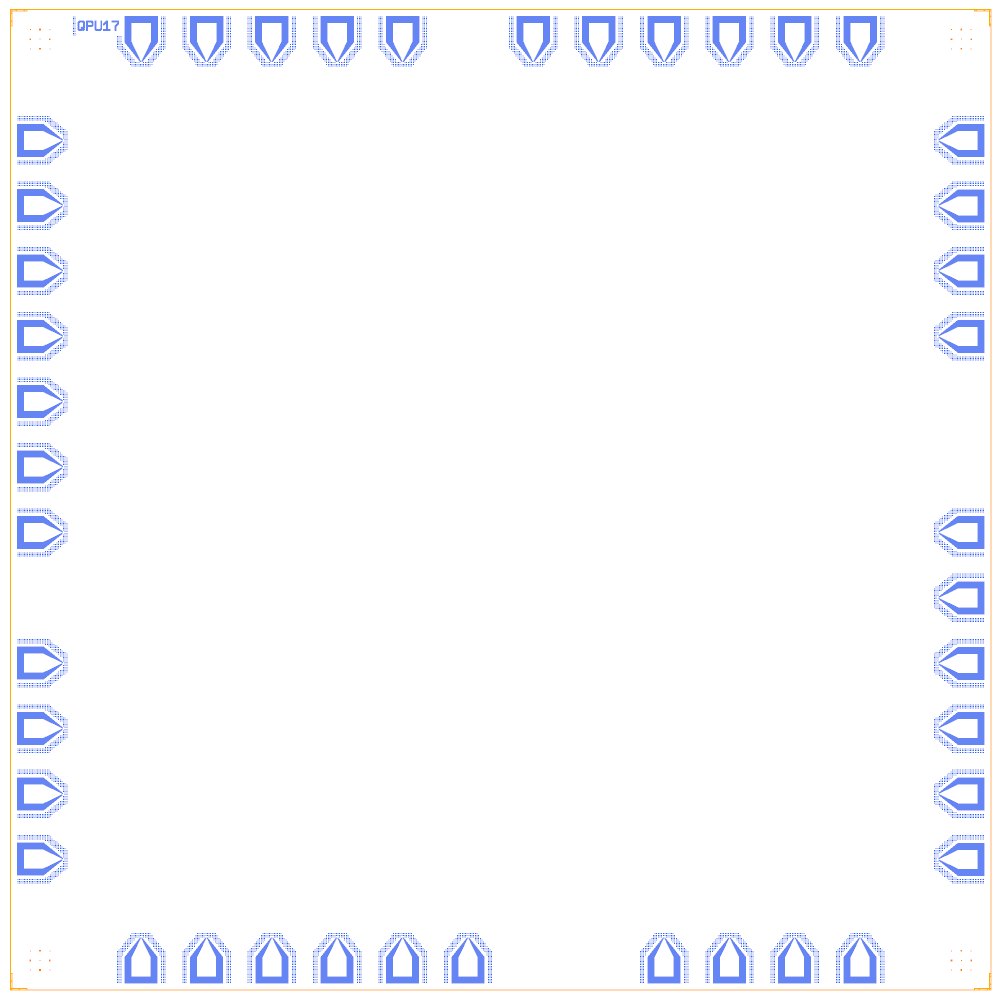

| pad | asked at (x, y) µm | outer etch edge → die edge (µm) |
|---|---|---|
| `L1` | (2000, 14100) | 100.0 |
| `L2` | (3000, 14100) | 100.0 |
| `L3` | (4000, 14100) | 100.0 |
| `L4` | (5000, 14100) | 100.0 |
| … | | |

In [7]:
INST = PLAN["instances"]


def add(names):
    """Add plan instances (with their junctions) in one rebuild."""
    with d.batch():
        for n in names:
            s = INST[n]
            params, jj = JJ.get(n, ({}, None))
            d.add(n, s["cell"], at=tuple(s["at"]), rot=s["rot"], **({"junction": jj} if jj else {}),
                  **({"edge": "auto"} if s["cell"] == "BondPad" else {}), **s["params"], **params)


d = Designer("t03_demoqpu17", box=(0, 0, W, H), chip={"name_chip": "QPU17"}, live=LIVE)
add([n for n, s in INST.items() if s["cell"] == "BondPad"])
print(Counter(s["cell"] for s in INST.values()))
T.snap(d, "pads", size=(1000, 1000), width=420)
T.md("\n".join(T.pad_edges_md(d).splitlines()[:6]) + "\n| … | | |")

## A6 · Components: 17 StarQubits, 17 tees, 4 input capacitors

- `metal:StarQubit`: a star-shaped island in a 150 µm pocket with five pads — four couplers (E, N, W, S) and a
  readout pad on the qubit's readout diagonal. The SQUID sits in the gap between the E and N couplers. A narrower
  readout gap on the data qubits (8 µm vs 15 µm) stands in for their bigger readout coupler.
- `metal:CapNInterdigitalTee`: the capacitive tee where a Purcell filter taps its feedline (8 fingers, κ_filter ≈
  30 MHz).
- `FingerCapacitorSquare`: each feedline's series input capacitor, 700 µm from its input pad.

<metal:StarQubit Q33 ports=['pin_cpl1', 'pin_cpl2', 'pin_cpl3', 'pin_cpl4', 'pin_rdout', 'squid_a', 'squid_b']>


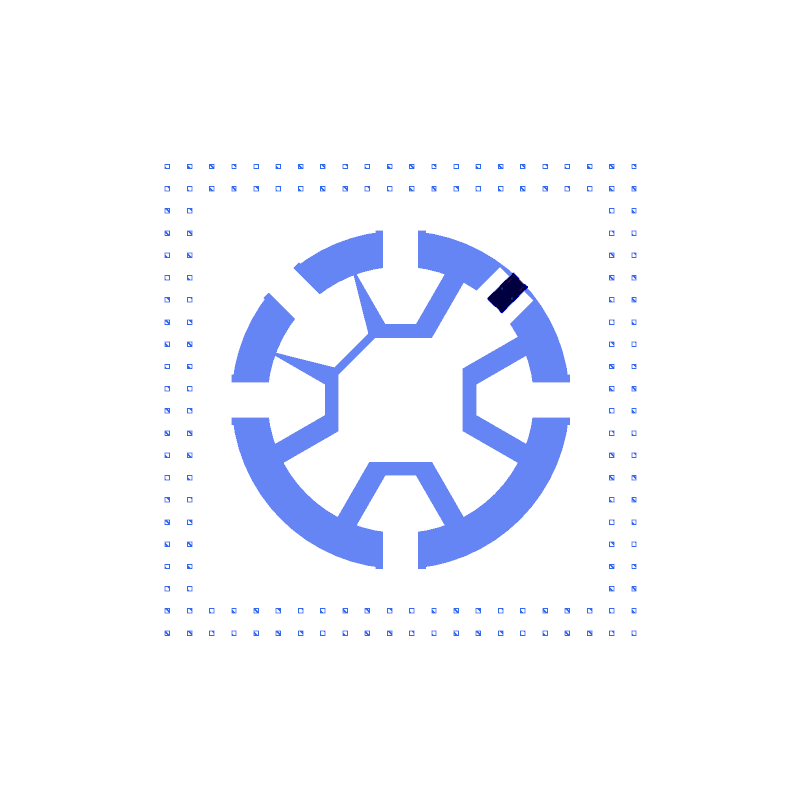

WindowsPath('examples/tutorials/img/t03_qubit.png')

In [8]:
add([n for n, s in INST.items() if s["cell"] in ("metal:StarQubit", "metal:CapNInterdigitalTee",
                                                  "FingerCapacitorSquare")])
print(d["Q33"])
T.snap(d, "qubit", box=(7500 - 450, 7500 - 450, 7500 + 450, 7500 + 450), size=(800, 800), width=340)

## A7 · Routes: couplers, readout modules, feedlines, control lines — and their airbridges

`S17.routes_of(line)` turns a planned line into qcc routes: one per section between its airbridges, the bridges
being `AirbridgeConnection` instances (`AB_<line>_<k>`) placed over the line below. Lines are added lowest rank
first:

1. **couplers** — straight 10/10 µm CPWs between facing coupler pads; the lowest rank, so other lines pass over
   them, never the other way round;
2. **readout modules** — the readout λ/4 hairpin from the readout pad, shorted at its end; the Purcell λ/4 hairpin from
   the tee's coupled port, shorted; the tap between them is a declared capacitance (`d.couple`, 1.2 fF, not drawn);
3. **feedlines** — pad → series capacitor → each tee in order → output pad (10/6 µm);
4. **Z then XY lines** — pad → strip beside the module → the SQUID (Z, shorted) or the drive end (XY, open).

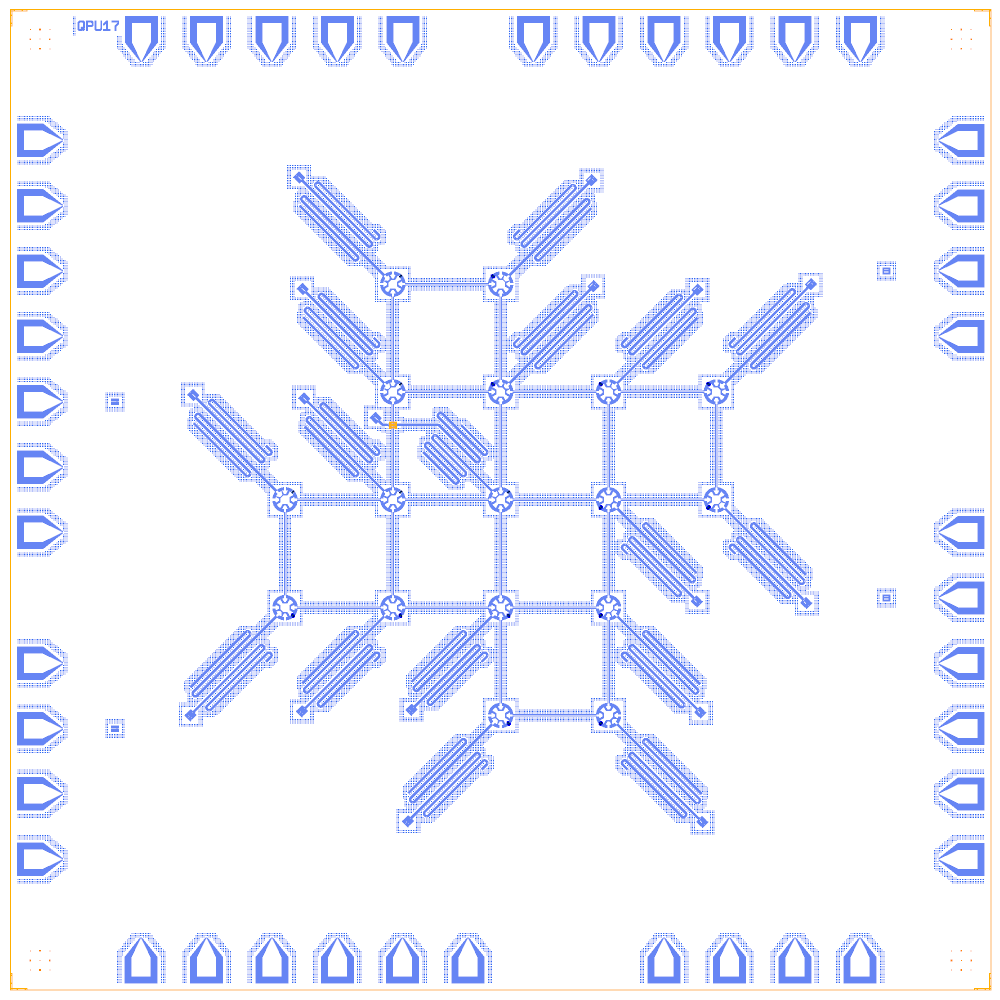

117 instances, 154 routes; not placed: none


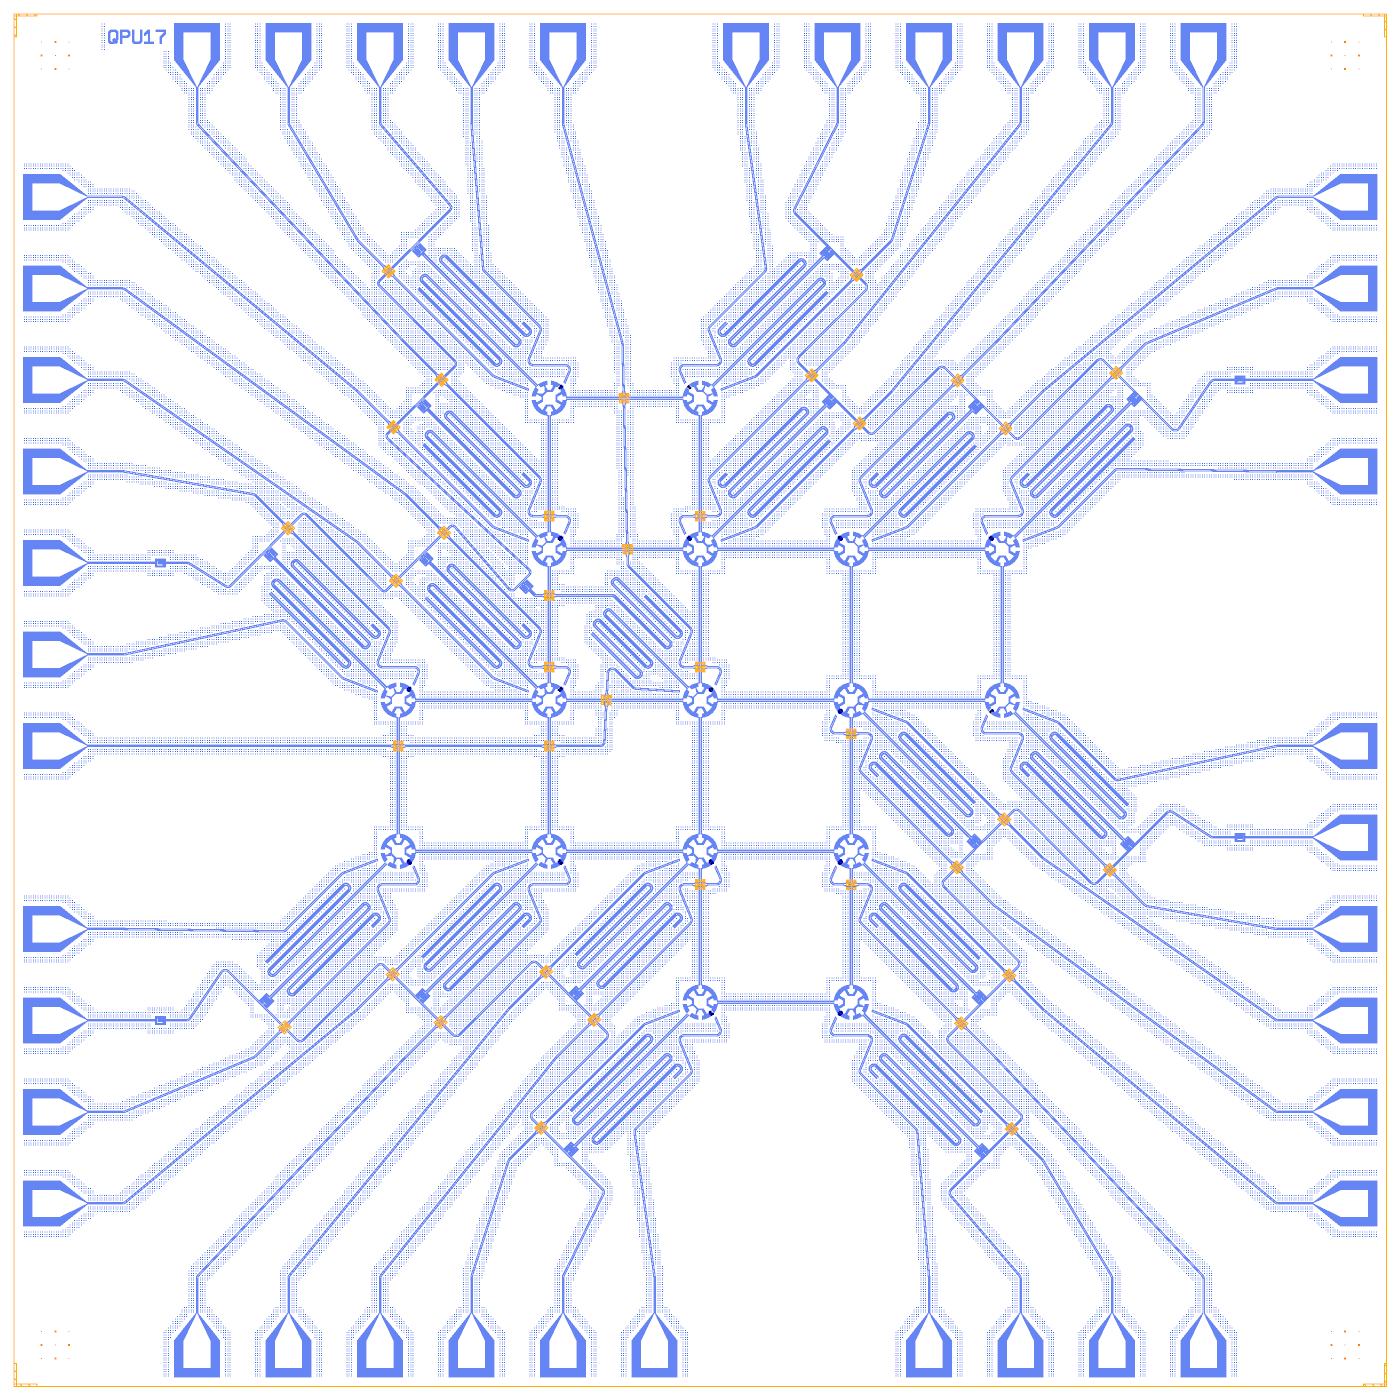

WindowsPath('examples/tutorials/img/t03_chip.png')

In [9]:
def add_lines(kinds):
    with d.batch():
        for line in PLAN["lines"]:
            if line.kind not in kinds:
                continue
            for k, b in enumerate(line.bridges):                 # the bridges this line passes over others on
                name = f"AB_{line.name}_{k}"
                s = INST[name]
                d.add(name, s["cell"], at=tuple(s["at"]), rot=s["rot"], **s["params"])
            for r in S17.routes_of(line):
                d.route(r["name"], r["start"], r["end"], type="cpw", nodes=[tuple(n) for n in r["nodes"]],
                        a=line.a, b=line.b, r=line.r)


add_lines({"coupler"})
add_lines({"resonator"})
for name, a, b, c, note in PLAN["couplings"]:
    d.couple(name, a, b, C_fF=c, note=note)
T.snap(d, "modules", size=(1000, 1000), width=420)
add_lines({"feed"})
add_lines({"z", "xy"})
missing = set(INST) - set(d.data["instances"])
print(len(d.data["instances"]), "instances,", len(d.data["routes"]), "routes; not placed:", missing or "none")
T.snap(d, "chip", size=(1400, 1400), width=620)

## A8 · DRC

Zero errors. Warnings: `dangling_port` on the qubits' `squid_a/b` (junction attachment points) and on the 20 coupler
pads of edge qubits with no neighbour on that side (DeviceLayout grounds them; here they stay free). PDK design
warnings: `pdk_rn` on any qubit whose device R_n falls outside 40–50 kΩ (see A4). There are no `pad_edge` warnings: the pads
moved to 100 µm.

In [10]:
rep = T.drc(d)
T.md(T.drc_md(rep, examples=1))
T.md(C.pdk_report(d).split("| pdk_rn |")[0])

**DRC clean** — 0 errors, 54 warnings, 12 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 54 | Q12.pin_cpl2 is not connected (no route or snap) |
| design | `pdk_rn` | 12 | Q12: junction R_n 53.6 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0172 nH) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 17 |
| PDK design warnings | 12 (pdk_rn × 12) |


## A9 · Netlist and LOM: the 17-qubit node structure

- each `StarQubit`: a grounded island with its SQUID, plus a node per pad;
- each coupler: a wire joining two coupler pads into one node (C_g – node – C_g between the qubits);
- each readout and each filter: a λ/4 `TLres`; the readout's open end on the readout-pad node, the filter's on the
  tee's coupled node; the tee's IDC joins that to the feedline node; `K_<q>` is the tap;
- each feedline: one node carrying its tees, with a 50 Ω port behind the input capacitor and one at the output pad;
- XY / Z lines: stubs on their pads (no drive / flux control yet: `StarQubit` has no drive or flux port).

In [11]:
lb = d.lom()
m = lb.model
print(C.netlist_md(lb).splitlines()[0])
print(Counter(b.type for b in m.branches.values()))


def tl(name):
    return next((b for n, b in m.branches.items() if b.type == "TLres" and n.startswith(name)), None)


rows = ["| qubit | role | coupled to | readout λ/4 (GHz) · open end | Purcell λ/4 (GHz) · open end | feedline node |",
        "|---|---|---|---|---|---|"]
for (r, c), qn in LABELS.items():
    nb = [b if a == qn else a for _, a, b in CPLS if qn in (a, b)]
    ro, pf = tl(f"RO_{qn}"), tl(f"PF_{qn}")
    rows.append(f"| {qn} | {'data' if qn in DATA else 'aux'} | {', '.join(nb)} | {(ro.value or {}).get('f_GHz', 0):.3f} · "
                f"`{ro.nodes[0]}` | {(pf.value or {}).get('f_GHz', 0):.3f} · `{pf.nodes[0]}` | "
                f"`{lb.port_map.get(f'T_{qn}.prime_start')}` |")
T.md("\n".join(rows))

**138 nodes · 351 branches · 0 controls · 20 unconnected ports**
Counter({'C': 250, 'R': 42, 'TLres': 42, 'SQUID': 17})


| qubit | role | coupled to | readout λ/4 (GHz) · open end | Purcell λ/4 (GHz) · open end | feedline node |
|---|---|---|---|---|---|
| Q12 | aux | Q13, Q22 | 7.292 · `Q12.pin_rdout` | 7.384 · `T_Q12.second` | `T_Q12.prime` |
| Q13 | data | Q12, Q23 | 7.604 · `Q13.pin_rdout` | 7.700 · `T_Q13.second` | `T_Q13.prime` |
| Q22 | data | Q12, Q23, Q32 | 7.708 · `Q22.pin_rdout` | 7.806 · `T_Q22.second` | `T_Q12.prime` |
| Q23 | aux | Q13, Q22, Q24, Q33 | 7.396 · `Q23.pin_rdout` | 7.489 · `T_Q23.second` | `T_Q13.prime` |
| Q24 | data | Q23, Q25, Q34 | 7.813 · `Q24.pin_rdout` | 7.911 · `T_Q24.second` | `T_Q13.prime` |
| Q25 | aux | Q24, Q35 | 7.187 · `Q25.pin_rdout` | 7.278 · `T_Q25.second` | `T_Q13.prime` |
| Q31 | data | Q32, Q41 | 7.500 · `Q31.pin_rdout` | 7.595 · `T_Q31.second` | `T_Q12.prime` |
| Q32 | aux | Q22, Q31, Q33, Q42 | 7.917 · `Q32.pin_rdout` | 8.017 · `T_Q32.second` | `T_Q12.prime` |
| Q33 | data | Q23, Q32, Q34, Q43 | 7.083 · `Q33.pin_rdout` | 7.178 · `T_Q33.second` | `T_Q12.prime` |
| Q34 | aux | Q24, Q33, Q35, Q44 | 7.917 · `Q34.pin_rdout` | 8.017 · `T_Q34.second` | `T_Q34.prime` |
| Q35 | data | Q25, Q34 | 7.708 · `Q35.pin_rdout` | 7.806 · `T_Q35.second` | `T_Q34.prime` |
| Q41 | aux | Q31, Q42 | 7.187 · `Q41.pin_rdout` | 7.278 · `T_Q41.second` | `T_Q41.prime` |
| Q42 | data | Q32, Q41, Q43 | 7.604 · `Q42.pin_rdout` | 7.700 · `T_Q42.second` | `T_Q41.prime` |
| Q43 | aux | Q33, Q42, Q44, Q53 | 7.813 · `Q43.pin_rdout` | 7.911 · `T_Q43.second` | `T_Q41.prime` |
| Q44 | data | Q34, Q43, Q54 | 7.500 · `Q44.pin_rdout` | 7.595 · `T_Q44.second` | `T_Q34.prime` |
| Q53 | data | Q43, Q54 | 7.396 · `Q53.pin_rdout` | 7.489 · `T_Q53.second` | `T_Q41.prime` |
| Q54 | aux | Q44, Q53 | 7.292 · `Q54.pin_rdout` | 7.384 · `T_Q54.second` | `T_Q34.prime` |

## A10 · LOM simulation against the targets

Each qubit with its readout chain (readout λ/4, tap, Purcell λ/4, tee) and its *whole* feedline (all its tees, the
input capacitor, both 50 Ω ports): QuTiP dressed values, targets in brackets. Expected: f_q within ≈ 5 % of the
plan, f_r within ≈ 1–3 %, the filter resonant with its readout with κ_filter ≈ 30 MHz, κ_readout a few MHz through
the filter, χ ≈ −5 … −15 MHz (the StarQubit LOM pads are rough).

In [12]:
def feed(ln, fls=FEEDLINES):
    spec = fls[ln]
    return [spec["pad_in"], spec["pad_out"], f"CIN_{ln}", *[r for r in d.data["routes"] if r.startswith(f"FL{ln}_")],
            *[f"T_{x}" for x in spec["qubits"]]]


def chain(qn):
    return [qn, *[r for r in d.data["routes"] if r.startswith((f"RO_{qn}", f"PF_{qn}"))],
            *[i for i in d.data["instances"] if i.startswith((f"AB_RO_{qn}", f"AB_PF_{qn}"))]]


GROUPS = {qn: chain(qn) + feed(ln) for ln, spec in FEEDLINES.items() for qn in spec["qubits"]}
d.targets(**{qn: {"f_q_GHz": F_Q[qn]} for qn in LABELS.values()},
          **{f"RO_{qn}": {"f_GHz": F_RO[qn]} for qn in LABELS.values()})
res = C.simulate_groups(d, GROUPS, max_modes=3)
T.md(C.groups_md(res, d.data["targets"]))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q31 | Q31 | 4.8135 (4.95) | -219.4 | RO_Q31 | 7.1376 (7.2) | 4.97 | -9.88 |
|  | – | – | – | PF_Q31 | 7.1809 | 32.4 | -1.18 |
| Q32 | Q32 | 5.7739 (5.95) | -207.7 | PF_Q32 | 7.544 | 38.2 | -3.25 |
|  | – | – | – | RO_Q32 | 7.5883 (7.6) | 5.12 | -11.3 |
| Q33 | Q33 | 4.8094 (5) | -217.1 | RO_Q33 | 6.7664 (6.8) | 4.54 | -11.9 |
|  | – | – | – | PF_Q33_1 | 6.8063 | 27.5 | -1.26 |
| Q22 | Q22 | 4.6712 (4.85) | -223.7 | RO_Q22 | 7.3204 (7.4) | 4.33 | -8.46 |
|  | – | – | – | PF_Q22 | 7.369 | 35.9 | -0.904 |
| Q12 | Q12 | 5.5361 (5.8) | -208.9 | PF_Q12 | 6.9833 | 31.4 | -4.34 |
|  | – | – | – | RO_Q12 | 7.02 (7) | 3.16 | -13.5 |
| Q25 | Q25 | 5.6469 (5.9) | -202.1 | PF_Q25 | 6.8895 | 31.3 | -4.04 |
|  | – | – | – | RO_Q25 | 6.9322 (6.9) | 1.96 | -17.9 |
| Q24 | Q24 | 4.6718 (4.9) | -224 | RO_Q24 | 7.4131 (7.5) | 4.42 | -8.2 |
|  | – | – | – | PF_Q24 | 7.4631 | 37.5 | -0.879 |
| Q23 | Q23 | 5.6525 (5.85) | -205.9 | PF_Q23 | 7.078 | 33.1 | -4.04 |
|  | – | – | – | RO_Q23 | 7.1178 (7.1) | 2.95 | -14.7 |
| Q13 | Q13 | 4.6706 (4.8) | -223.4 | RO_Q13 | 7.2276 (7.3) | 4.31 | -8.74 |
|  | – | – | – | PF_Q13 | 7.2748 | 34.6 | -0.933 |
| Q35 | Q35 | 4.8151 (5.05) | -220.2 | RO_Q35 | 7.323 (7.4) | 4.95 | -9.19 |
|  | – | – | – | PF_Q35 | 7.3694 | 35.4 | -1.08 |
| Q34 | Q34 | 5.7739 (6) | -207.7 | PF_Q34 | 7.544 | 38.3 | -3.25 |
|  | – | – | – | RO_Q34 | 7.5883 (7.6) | 5.1 | -11.3 |
| Q44 | Q44 | 4.9509 (5.15) | -215.8 | RO_Q44 | 7.1406 (7.2) | 5.98 | -10.8 |
|  | – | – | – | PF_Q44 | 7.1814 | 31.5 | -1.47 |
| Q54 | Q54 | 5.8639 (6.15) | -193.3 | PF_Q54 | 6.9849 | 33.3 | -3.51 |
|  | – | – | – | RO_Q54 | 7.0373 (7) | 1.38 | -22.9 |
| Q41 | Q41 | 5.7554 (6.05) | -196.5 | PF_Q41 | 6.8901 | 31.9 | -3.73 |
|  | – | – | – | RO_Q41 | 6.9387 (6.9) | 1.45 | -21.5 |
| Q42 | Q42 | 4.9519 (5.1) | -216.3 | RO_Q42 | 7.2332 (7.3) | 5.83 | -10.4 |
|  | – | – | – | PF_Q42 | 7.2756 | 33.1 | -1.38 |
| Q43 | Q43 | 5.8796 (6.1) | -202.9 | PF_Q43 | 7.4513 | 38.2 | -3.24 |
|  | – | – | – | RO_Q43 | 7.4988 (7.5) | 3.73 | -14 |
| Q53 | Q53 | 4.9498 (5.2) | -215.2 | RO_Q53 | 7.0479 (7.1) | 6.19 | -11.2 |
|  | – | – | – | PF_Q53 | 7.087 | 29.8 | -1.57 |

**A coupled pair.** Q23 (aux) and Q33 (data) through their 1.3 mm coupler: two qubit modes ≈ 0.9 GHz apart (no
hybridisation) and the static ZZ — large, because the StarQubit LOM gives every coupler pad the same arc and the
coupler route has no line capacitance in the LOM yet (a known LOM request); the `Q23_Q33` C-matrix job calibrates it.

In [13]:
pair = C.simulate_groups(d, {"Q23+Q33": ["Q23", "Q33", "CPL_Q23_Q33"]}, max_modes=2)
T.md(C.modes_md(pair["Q23+Q33"]) + "\n\n" + C.zz_md(pair))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q33 | qubit | 5.2048 | 0 | 207.9 | J_Q33 0.98, J_Q23 0.02 |
| Q23 | qubit | 6.0664 | 0 | 205.5 | J_Q23 0.98, J_Q33 0.02 |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q23+Q33 | Q23-Q33 | -2.064e+04 | yes | no |

> **Simulation PC (32 GB+ RAM).** The cells below render and solve the subset FEM jobs of the 17-qubit chip (`Q23_Q33` Q3D, the `Q12_readout` and `Q33_readout` eigenmodes with and without airbridges) in AEDT; the whole-chip job (`FEM_WHOLE`) and the whole-chip LOM are too big for a smaller PC. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## A11 · FEM: stage 1, the subset check — and the jobs with and without airbridges

| group | analysis | gives |
|---|---|---|
| `Q23_Q33` | `q3d_cmatrix` | the two qubits and their coupler: C_Σ, the pad capacitances, g |
| `Q12_readout` | `eigenmode_epr` | Q12 with its readout hairpin, tee and Purcell hairpin: f, κ, χ by EPR |
| `Q33_readout` | `eigenmode_epr` | Q33's closed-plaquette module, whose filter lead is **bridged** over a coupler |

Simulation exports never carry cheese, and **airbridges are dropped by default** (faster meshes); a note flags each
crossing bridge, whose line is then open at the crossing in the FEM model. `airbridges=True` (or the group setting
`settings={"airbridges": True}`, CLI `--airbridges`) keeps them. The whole chip is not solved here (a 17-qubit chip needs a
server; its jobs are ready for one); the `SIM_SUBSET` boxes are: one qubit and its readout chain, Q3D, about a minute. `RUN_FEM = True` **renders** the coupled pair `Q23_Q33` (Q3D, no solve) to show that the
components reach AEDT intact. The eigenmode groups are exported but not rendered here. Every port has a polygon: the
StarQubit's junction port spans the gap on the junction axis, and a feedline or control line that crosses the box
edge at 45° on this lattice gets its 50 Ω port on its own axis, cut square to the line (the builder notes below
list those ports).

**`AEDT_MODE`** (next to `RUN_FEM`): `"batch"` solves in a new non-graphical AEDT; `"gui"` opens a new AEDT window and leaves it open, so you watch the mesh, the convergence and the fields; `"attach"` runs inside the AEDT window you already have open (or opens one) and leaves the project there. Every mode prints a progress line (step, pass, mesh, ΔF / ΔS / ΔC) every 30 s, so a stuck run is visible; on a timeout only what qcc started is stopped.

In [14]:
from quantcore_circuits.sim_tools import build_simulation

FEM_FAST = T.fem_fast(FEM_FAST)                   # the switch from the top

d.sim_group("Q23_Q33", ["Q23", "Q33", "CPL_Q23_Q33"], margin_um=150, analyses=["q3d_cmatrix"])
d.sim_group("Q12_readout", ["Q12", "RO_Q12", "T_Q12", "PF_Q12"], margin_um=150, analyses=["eigenmode_epr"])
d.sim_group("Q33_readout", chain("Q33") + ["T_Q33"], margin_um=150, analyses=["eigenmode_epr"])
# SIM_SUBSET → one sim group per box ("whole" → the built-in group "chip": exported, not solved here)
SUB = T.sim_subset(d, SIM_SUBSET, name="SUB", margin_um=150, analyses=SUBSET_ANALYSES) if SIM_SUBSET else []
DESIGN = d.save(T.DESIGNS / "t03_demoqpu17.json")
jobs = C.export_sims(DESIGN, ["Q23_Q33"], "q3d_cmatrix")
jobs_eig = C.export_sims(DESIGN, ["Q12_readout", "Q33_readout"], "eigenmode_epr")
T.md(C.jobs_md(jobs) + "\n" + C.jobs_md(jobs_eig).split("\n", 2)[2])
for keep_ab in (False, True):
    s = build_simulation(DESIGN, "Q33_readout", "eigenmode_epr", airbridges=keep_ab)
    print(f"airbridges={keep_ab}: geometry {s.geometry} | notes {s.notes}")
# RUN_FEM, AEDT_MODE: the switches at the top (SIM_SUBSET cell)
sub_jobs = {a: C.export_sims(DESIGN, SUB, a) for a in SUBSET_ANALYSES} if SUB else {}
if sub_jobs:
    T.md(C.jobs_md(sub_jobs["q3d_cmatrix"]))
keeps = {(g, a): T.solve_or_load(sub_jobs[a][g][0], RUN_FEM, force=RESOLVE, aedt=AEDT_MODE, timeout=1800)
         for a in sub_jobs for g in SUB}          # one AEDT at a time
# the subset check, FEM only: convergence, the raw C-matrix, the FEM-filled capacitances next to the estimates
CHECK = T.subset_check({f"{g} · {a}": k for (g, a), k in keeps.items()}, d.lom().model, DESIGN)

FEM_FAST: jobs are exported with the fast test settings (q3d_cmatrix percent_error 2, maximum_passes 8, minimum_passes 1; hfss_driven max_delta_s 0.05, maximum_passes 6, minimum_passes 1; eigenmode_epr max_delta_f 1, maximum_passes 3, minimum_passes 1); values are not converged


**SIM_SUBSET = [('Q23', None)]** → 1 box(es); each is rendered and simulated on its own, and its values fill only these components of the whole-chip netlist:

| group (box) | qubits | readout chain | buses in | buses cut at the qubit | feedline (cut by the box) |
|---|---|---|---|---|---|
| `SUB` | Q23 | Q23: RO_Q23, PF_Q23, T_Q23 | – | CPL_Q13_Q23, CPL_Q22_Q23, CPL_Q23_Q24, CPL_Q23_Q33 | FL2_2, FL2_3 |

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q23_Q33 | `build/jobs/t03_demoqpu17_Q23_Q33_q3d_cmatrix` | 1 · junction · `Q23.junction`<br>2 · junction · `Q33.junction`<br>3 · waveguide · `Q23.pin_cpl4`<br>4 · waveguide · `Q33.pin_cpl2`<br>5 · edge · `CPL_Q13_Q23`<br>6 · edge · `CPL_Q32_Q33`<br>7 · edge · `CPL_Q33_Q34`<br>8 · edge · `CPL_Q33_Q43`<br>9 · edge · `CPL_Q23_Q24`<br>10 · edge · `XY_Q23_1`<br>11 · edge · `XY_Q33_3`<br>12 · edge · `CPL_Q22_Q23`<br>13 · edge · `Z_Q33_2` | `Q23.island`, `Q33.island`, `XY_Q23_1`, `XY_Q33_3`, `Z_Q33_2` |
| Q12_readout | `build/jobs/t03_demoqpu17_Q12_readout_eigenmode_epr` | 1 · junction · `Q12.junction`<br>2 · edge_lumped · `FL1_3`<br>3 · edge_lumped · `FL1_4`<br>4 · edge_lumped · `FL1_4`<br>5 · edge_lumped · `FL1_5`<br>6 · edge_lumped · `XY_Q12_1`<br>7 · edge_lumped · `CPL_Q12_Q13`<br>8 · edge_lumped · `CPL_Q12_Q22`<br>9 · edge_lumped · `Z_Q22`<br>10 · edge_lumped · `Z_Q22_1` | `Q12.island`, `FL1_3`, `FL1_4`, `FL1_4#2`, `FL1_5`, `XY_Q12_1`, `CPL_Q12_Q13`, `CPL_Q12_Q22`, `Z_Q22`, `Z_Q22_1` |
| Q33_readout | `build/jobs/t03_demoqpu17_Q33_readout_eigenmode_epr` | 1 · junction · `Q33.junction`<br>2 · edge_lumped · `CPL_Q31_Q32`<br>3 · edge_lumped · `CPL_Q33_Q34`<br>4 · edge_lumped · `CPL_Q33_Q43`<br>5 · edge_lumped · `FL1_2`<br>6 · edge_lumped · `FL1_3`<br>7 · edge_lumped · `XY_Q32_1`<br>8 · edge_lumped · `Z_Q32_1`<br>9 · edge_lumped · `Z_Q33_2`<br>10 · edge_lumped · `XY_Q33_2`<br>11 · edge_lumped · `CPL_Q32_Q42` | `Q33.island`, `CPL_Q31_Q32`, `CPL_Q33_Q34`, `CPL_Q33_Q43`, `FL1_2`, `FL1_3`, `XY_Q32_1`, `Z_Q32_1`, `Z_Q33_2`, `XY_Q33_2`, `CPL_Q32_Q42`, `Q33.pin_cpl3`, `AB_PF_Q33_0.line` |

airbridges=False: geometry {'ground_grid_shapes': 0, 'airbridge_shapes': 3, 'airbridges': 'dropped'} | notes ['Q33: junction port spans the gap on the junction axis from (7634.35, 7634.35) to (7606.07, 7606.07) µm (40.00 µm; the drawn pins (7621.98, 7621.98) / (7646.73, 7646.73) are not on the metal edges), sheet 10 µm wide', 'Q33: junction L 10.52 nH, C 9.6 fF (design; Φ = 0, d = 0)', "4 50 Ω port(s) on the line's own axis (FL1_2 49°, FL1_3 47°, XY_Q32_1 21°, Z_Q32_1 45° from the box edge's normal): the box edge crosses these lines at an angle, so each port cuts its line square, just inside the box (the short piece out to the box edge stays metal, as at a square crossing)"]


airbridges=True: geometry {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'} | notes ['Q33: junction port spans the gap on the junction axis from (7634.35, 7634.35) to (7606.07, 7606.07) µm (40.00 µm; the drawn pins (7621.98, 7621.98) / (7646.73, 7646.73) are not on the metal edges), sheet 10 µm wide', 'Q33: junction L 10.52 nH, C 9.6 fF (design; Φ = 0, d = 0)', "4 50 Ω port(s) on the line's own axis (FL1_2 49°, FL1_3 47°, XY_Q32_1 21°, Z_Q32_1 45° from the box edge's normal): the box edge crosses these lines at an angle, so each port cuts its line square, just inside the box (the short piece out to the box edge stays metal, as at a square crossing)"]


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| SUB | `build/jobs/t03_demoqpu17_SUB_q3d_cmatrix` | 1 · junction · `Q23.junction`<br>2 · waveguide · `Q23.pin_cpl2`<br>3 · waveguide · `Q23.pin_cpl3`<br>4 · waveguide · `Q23.pin_cpl1`<br>5 · waveguide · `Q23.pin_cpl4`<br>6 · waveguide · `Q23.pin_rdout`<br>7 · waveguide · `T_Q23.second_end`<br>8 · edge · `CPL_Q24_Q34`<br>9 · edge · `FL2_2`<br>10 · edge · `FL2_3`<br>11 · edge · `XY_Q13_1`<br>12 · edge · `XY_Q23_1`<br>13 · edge · `CPL_Q12_Q13` | `Q23.island`, `T_Q23.second_end`, `FL2_2`, `XY_Q13_1`, `XY_Q23_1` |

| analysis | passes | tets (last) | criterion | last Δ / target | converged | wall time (s) |
|---|---|---|---|---|---|---|
| SUB · q3d_cmatrix | 8 | 16936 | Delta % | 2.69 / 2.0 | False | 54.6 |

Q3D C-matrix of `t03_demoqpu17_SUB_q3d_cmatrix` (2024.1.0, 54.6 s; Maxwell form, fF):

| net | `T_Q23.second_end` | `FL2_2` | `XY_Q13_1` | `XY_Q23_1` | `Q23.island` |
|---|---|---|---|---|---|
| `T_Q23.second_end` | 32.528 | -24.640 | -0.002 | -0.019 | -0.001 |
| `FL2_2` | -24.640 | 93.454 | -0.004 | -0.047 | -0.003 |
| `XY_Q13_1` | -0.002 | -0.004 | 44.002 | -0.003 | -0.002 |
| `XY_Q23_1` | -0.019 | -0.047 | -0.003 | 259.836 | -0.110 |
| `Q23.island` | -0.001 | -0.003 | -0.002 | -0.110 | 87.430 |

**FEM-filled capacitances of the simulated components** (the other branches keep their estimates):

| branch | nodes | estimate | FEM | from |
|---|---|---|---|---|

**0** branches filled from FEM; **250** kept their estimates (236 outside the subset, e.g. `C_Q12`, `Cg_Q12_pin_cpl1`, `Cc_Q12_pin_cpl1`, `Cg_Q12_pin_cpl2`, `Cc_Q12_pin_cpl2`, `Cg_Q12_pin_cpl3`).
- `t03_demoqpu17_SUB_q3d_cmatrix` (group `SUB`, q3d_cmatrix): 0 branches; scope PF_Q23, Q23, RO_Q23, T_Q23

**Look at these before the whole chip:** if the passes converged (or Δ sits near its target), the capacitances are positive and near their estimates and the qubit mode has p_J ≈ 1, go on and render and simulate the whole chip (stage 2). If not, change the mesh / settings here first: a subset solves in minutes.

**Render: the components in AEDT.** `T.render_or_load` runs `hfss.render(..., solve=False)` — one new batch AEDT
that imports the cut-out, assigns materials, sheets, nets and the setup, and saves the `.aedt` project (no mesh, no
solve) — and reads it back with `hfss.check_project`. The check is kept in
`examples/tutorials/fem/t03_demoqpu17_Q23_Q33_q3d_cmatrix/check.json`. The second part lists what the builder
reports for the eigenmode group `Q12_readout` (`SimSetup.notes`).

In [15]:
import warnings

rendered = T.render_or_load(DESIGN, "Q23_Q33", "q3d_cmatrix", RUN_FEM, aedt=AEDT_MODE)   # RUN_FEM: render now; else the kept check
if rendered:
    T.md(T.check_md(rendered))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    notes = build_simulation(DESIGN, "Q12_readout", "eigenmode_epr").notes
T.md("**`Q12_readout` (eigenmode), builder notes:**\n\n" + "\n".join(f"- {n}" for n in notes))

`t03_demoqpu17_Q23_Q33_q3d_cmatrix`: Q3D Extractor / None, rendered in 20.5 s; 11 boundaries, nets ['Net1', 'Net2', 'Net3', 'Net4', 'Net5'] — **OK**

| check | ok | detail |
|---|---|---|
| design type | ✓ | Q3D Extractor / None |
| substrate_1 stack | ✓ | sapphire εr 10.25, 650 µm (PDK 10.25, 650 µm) |
| metal sheets ThinConductor | ✓ | 10/10 sheets |
| net Net1 = XY_Q23_1 | ✓ | objects ['1t1_signal_1_2'] |
| net Net2 = XY_Q33_3 | ✓ | objects ['1t1_signal_2_1'] |
| net Net3 = Z_Q33_2 | ✓ | objects ['1t1_signal_3_3'] |
| net Net4 = Q33.island | ✓ | objects ['1t1_signal_4_4'] |
| net Net5 = Q23.island | ✓ | objects ['1t1_signal_5_5'] |
| no unlabelled signal nets | ✓ |  |
| settings read back | ✓ | 4 keys |

**`Q12_readout` (eigenmode), builder notes:**

- Q12: junction port spans the gap on the junction axis from (5984.35, 10934.35) to (5956.07, 10906.07) µm (40.00 µm; the drawn pins (5971.98, 10921.98) / (5996.73, 10946.73) are not on the metal edges), sheet 10 µm wide
- Q12: junction L 8.017 nH, C 12.6 fF (design; Φ = 0, d = 0)
- 7 50 Ω port(s) on the line's own axis (FL1_3 45°, FL1_4 45°, FL1_4 45°, FL1_5 45°, XY_Q12_1 45°, Z_Q22 46°, Z_Q22_1 45° from the box edge's normal): the box edge crosses these lines at an angle, so each port cuts its line square, just inside the box (the short piece out to the box edge stays metal, as at a square crossing)

> **Simulation PC (32 GB+ RAM).** The cells below fill the 17-qubit LOM from the subset FEM and simulate it one qubit group at a time; the LOM vs FEM check and the StarQubit pin-port fix need fresh converged FEM results and the big chip. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

**Stage 2: the subset values in the whole LOM.** `fill(d.lom().model, DESIGN, q3d)` fills the branches the subset
jobs simulated into the whole chip's netlist (17 qubits); every other branch keeps its estimate and says so. The LOM
then runs on that whole netlist, one qubit group at a time (the groups of section A9). `FEM_WHOLE = True` renders the
whole chip (`T.render_or_load(DESIGN, "chip", "q3d_cmatrix", RUN_FEM)`: geometry, nets, ports, setup; no solve) — its
job is ready for a server.

**What comes back today (2026-11-14, FEM_FAST):** the Q3D of `SUB` solves in ≈ 1 min, but the StarQubit's pin stubs
get no excitation (their waveguide ports have no polygon on this 45° lattice), so its coupler and readout pads are
*ground* in that C-matrix. `fill` sees that the qubit's pin nodes have no net and keeps the estimates of its ground
branches (a note says so): **the LOM values of this chip are the component estimates** until the StarQubit pin ports
are fixed (open issue).

In [16]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

q3d = [x for (g, a), x in keeps.items() if a == "q3d_cmatrix" and x]
filled = fill(d.lom().model, DESIGN, q3d)          # the whole 17-qubit netlist; unsimulated branches keep estimates
n_fem = sum(1 for v in filled.values.values() if v.type == "C" and v.extracted is not None)
rows = []
for qn in [q for box in getattr(d, "subset_plan", []) for q in box.qubits]:   # the simulated qubits' groups
    a = res[qn].params
    b = simulate(fill(d.lom(select=GROUPS[qn]).model, DESIGN, q3d), max_modes=3).params
    rows += [(f"{qn} f_q (GHz)", a.get(f"{qn}.f_q_GHz"), b.get(f"{qn}.f_q_GHz"), "LOM on the filled netlist"),
             (f"RO_{qn} f_r (GHz)", a.get(f"RO_{qn}.f_GHz"), b.get(f"RO_{qn}.f_GHz"), "LOM on the filled netlist")]
if rows:
    T.md(T.fem_vs_lom_md(rows))
print(f"{n_fem} capacitances of the whole netlist came from FEM"
      + ("" if n_fem else ": the LOM values of this chip are the component estimates (StarQubit pin guard)"))
rendered_chip = T.render_or_load(DESIGN, "chip", "q3d_cmatrix", RUN_FEM and FEM_WHOLE, aedt=AEDT_MODE, timeout=3600)
if rendered_chip:
    T.md(T.check_md(rendered_chip))

| quantity | LOM (component estimates) | FEM / LOM on FEM values | Δ | note |
|---|---|---|---|---|
| Q23 f_q (GHz) | 5.652 | 5.652 | +0.0 % | LOM on the filled netlist |
| RO_Q23 f_r (GHz) | 7.118 | 7.118 | +0.0 % | LOM on the filled netlist |

0 capacitances of the whole netlist came from FEM: the LOM values of this chip are the component estimates (StarQubit pin guard)
t03_demoqpu17_chip_q3d_cmatrix: not rendered yet (examples/tutorials/fem/t03_demoqpu17_chip_q3d_cmatrix/check.json); RUN_FEM = True renders it


## A12 · Iterate: one geometry change on one qubit

Q13 is a data qubit with the narrow 8 µm readout gap. Widen it to 15 µm (the auxiliary value) on a copy of the
design: the readout pad's coupling to the island drops, so |χ| and the qubit's pull on its readout drop. Its pins do
not move (they sit at 1.25 × the pocket radius), so every route stays where it is.

In [17]:
d2 = Designer.load(DESIGN, live=LIVE, out="build/t03_demoqpu17_rev1.oas")
d2["Q13"].set(gap_readout=15)
g13 = {"Q13": GROUPS["Q13"]}
before = T.lom_params(res["Q13"], ["Q13.f_q_GHz", "Q13.alpha_MHz", "RO_Q13.f_GHz", "RO_Q13.chi_MHz",
                                   "RO_Q13.kappa_MHz"])
after = T.lom_params(C.simulate_groups(d2, g13, max_modes=3)["Q13"], list(before))
T.md(T.before_after_md(before, after))
print("DRC after the change:", "clean" if T.drc(d2).ok else "ERRORS")

| quantity | before | after | change |
|---|---|---|---|
| `Q13.f_q_GHz` | 4.6706 | 4.7488 | +0.07823 (+1.7 %) |
| `Q13.alpha_MHz` | -223.38 | -233.24 | -9.86 (-4.4 %) |
| `RO_Q13.f_GHz` | 7.2276 | 7.2884 | +0.06075 (+0.8 %) |
| `RO_Q13.chi_MHz` | -8.7361 | -4.1378 | +4.598 (+52.6 %) |
| `RO_Q13.kappa_MHz` | 4.3148 | 13.327 | +9.013 (+208.9 %) |

DRC after the change: clean


## A13 · Build and export

The fab export keeps the build's cheese (the PDK band) and rounds the corners; the airbridge layers go to 300/0
(pads) and 301/0 (bridges). CLI: `qcc build examples/tutorials/designs/t03_demoqpu17.json`, `qcc mask …`,
`qcc sim build … -g Q12_readout -a eigenmode_epr`, `qcc hfss render … -g Q33_readout -a eigenmode_epr --airbridges`.

In [18]:
import warnings
from quantcore_circuits.layouts.wafers.fab_export import export_fab

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rep_fab = {}
    fab = export_fab(T.built(d), "build/t03_demoqpu17_fab.oas", report=rep_fab)
T.md(T.fab_report_md(rep_fab, fab))

`build/t03_demoqpu17_fab.oas`: cheese **build** (81776 holes)

| fab layer | polygons |
|---|---|
| `AIRBRIDGE_BRIDGE` | 111 |
| `AIRBRIDGE_PADS` | 222 |
| `CHIP_BOUNDARY` | 1 |
| `HSQ` | 68 |
| `JJ_BENT` | 17 |
| `JJ_STRAIGHT` | 17 |
| `M1` | 81955 |
| `M3` | 81781 |
| `MARKERS_ALIGN` | 36 |
| `MARKERS_DICING` | 4 |
| `SPACER_1` | 68 |
| `SPACER_2` | 68 |
| `SPACER_3` | 68 |

## A14 · Snapshots

The centre plaquette (Q33's shortened hairpin, its tee in the west channel, bridged lines), one readout module
(hairpins and tee), Q33's trilayer SQUID, one airbridge, and the fab view of a module.

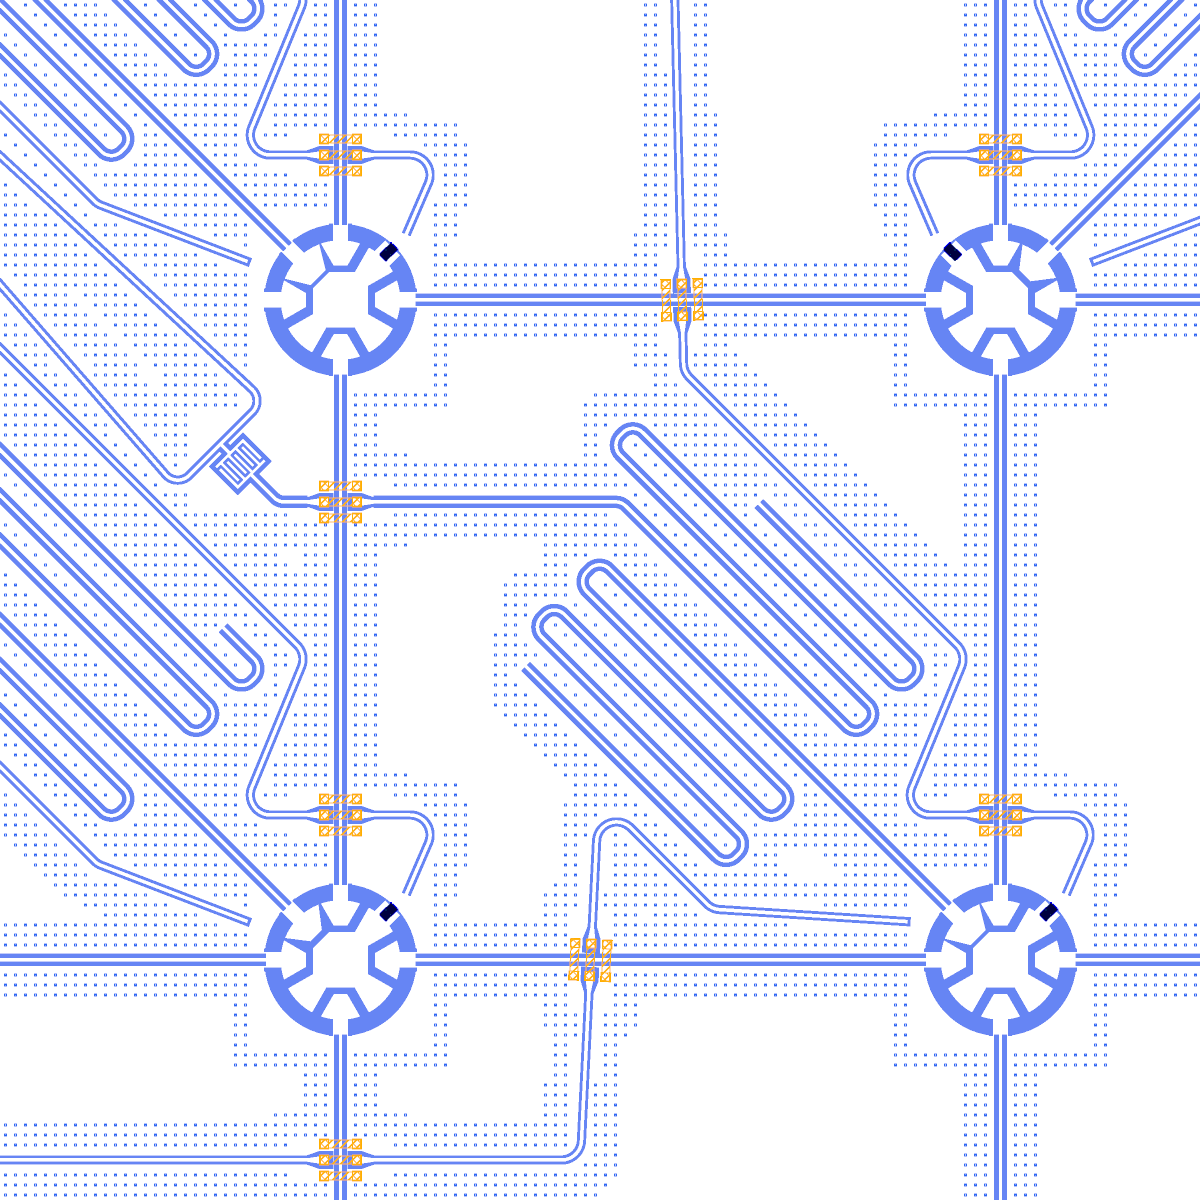

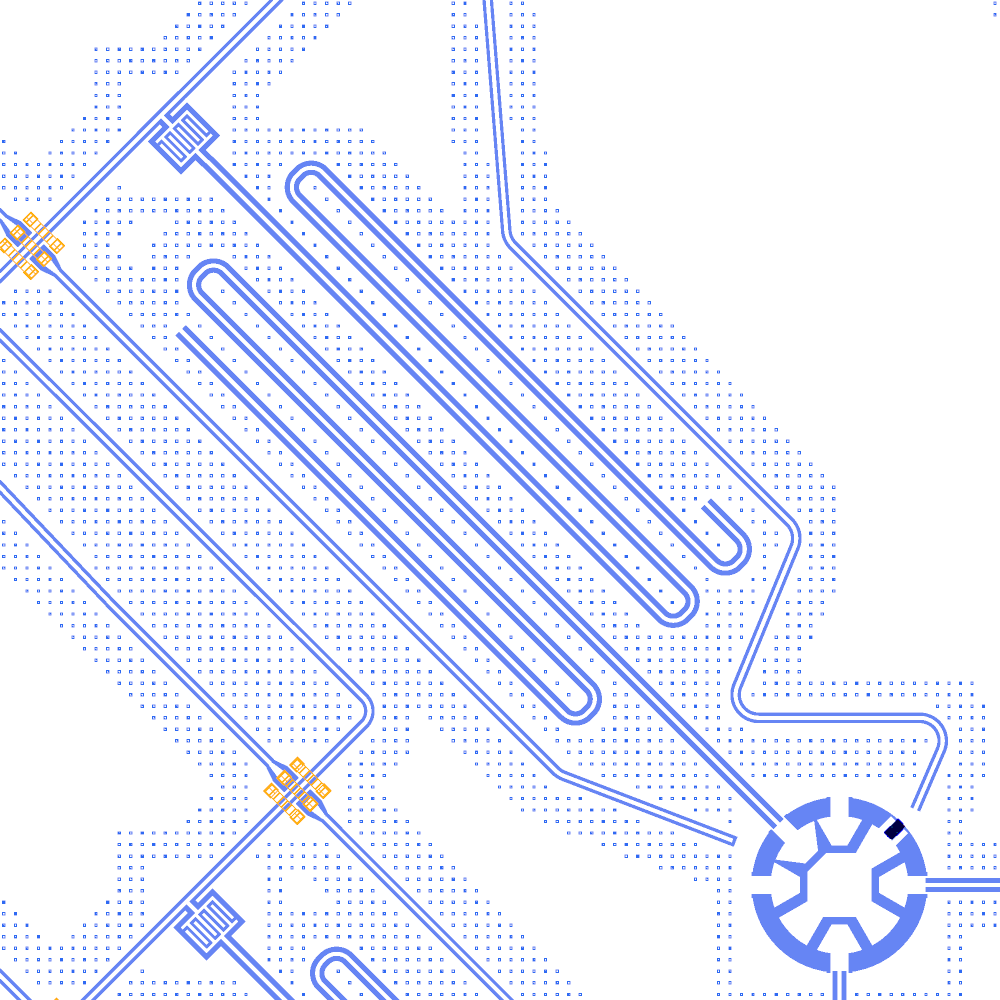

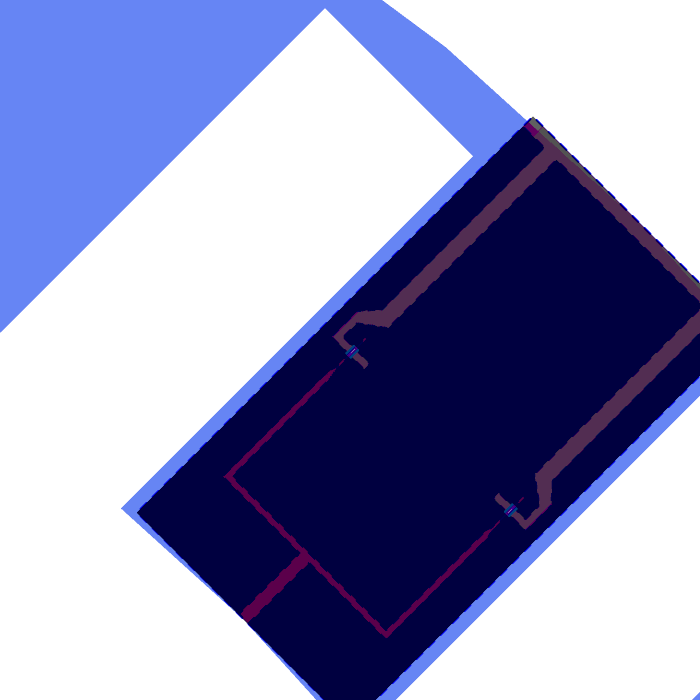

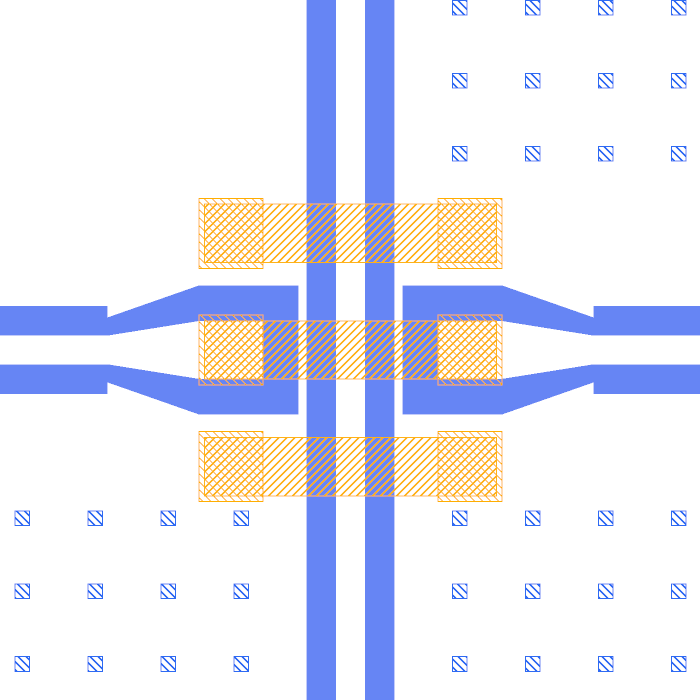

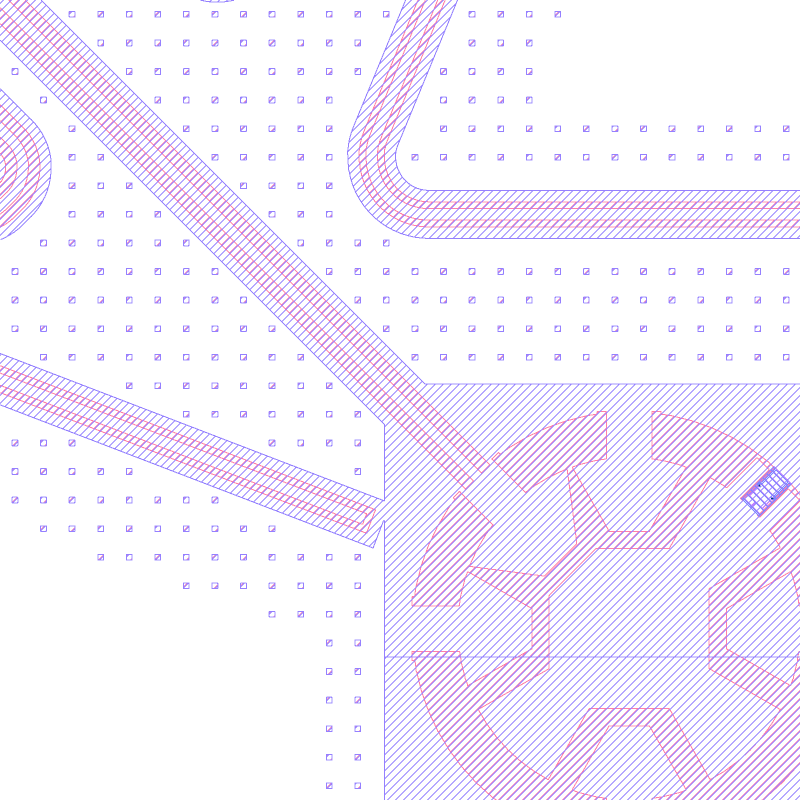

WindowsPath('examples/tutorials/img/t03_fab_module.png')

In [19]:
T.snap(d, "centre", box=(5000, 6900, 8000, 9900), size=(1200, 1200), width=520)
(xq, yq), (xt, yt) = INST["Q12"]["at"], INST["T_Q12"]["at"]          # Q12 and its tee: the module between
box = (min(xq, xt) - 250, min(yq, yt) - 250, max(xq, xt) + 250, max(yq, yt) + 250)
T.snap(d, "module", box=box, size=(1000, 1000), width=420)
T.snap(d, "squid", box=T.junction_box(d, "Q33", half=25), size=(700, 700), width=280)
ab = PLAN["bridges"][0]["at"]
T.snap(d, "bridge", box=(ab[0] - 120, ab[1] - 120, ab[0] + 120, ab[1] + 120), size=(700, 700), width=280)
T.snap(d, "fab_module", box=(xq - 550, yq - 150, xq + 150, yq + 550), size=(800, 800), width=380, source=fab)  # NW: the module runs up-left

# Part B · The ETH Zurich 17-qubit device, from the same generator

The same steps with a different `Config`: the mock-up's lattice pitch (1609.2 × 1753.9 µm) and pad slots, the paper's
names (D1–D9, X1–X4, Z1–Z4) and Table I targets, D5 in the closed plaquette, a larger StarQubit (180 µm radius) so
that α lands near the paper's −164 … −192 MHz. Here the whole plan is added in one call (`S17.build`, inside one
`d.batch()`), then `C.pads_to_edge(d)` applies the pad rule to every pad at once.

In [20]:
WE = HE = 14400.0
C0 = WE / 2
SITES = {(1, 2): "Z1", (1, 3): "D1", (2, 2): "D4", (2, 3): "X2", (2, 4): "D2", (2, 5): "X1", (3, 1): "D7",
         (3, 2): "Z2", (3, 3): "D5", (3, 4): "Z3", (3, 5): "D3", (4, 1): "X4", (4, 2): "D8", (4, 3): "X3",
         (4, 4): "D6", (5, 3): "D9", (5, 4): "Z4"}
GROUP = {"NW": ["Z1", "D4", "Z2", "D7"], "NE": ["X1", "D2", "D5", "X2", "D1"],
         "SE": ["Z4", "D6", "Z3", "D3"], "SW": ["X4", "D8", "X3", "D9"]}
QUAD_E = {qn: g for g, qs in GROUP.items() for qn in qs}
F_Q_E = {"D1": 3.885, "D2": 3.994, "D3": 3.952, "D4": 3.878, "D5": 3.895, "D6": 3.74, "D7": 4.056, "D8": 3.993,
         "D9": 4.143, "X1": 6.097, "X2": 5.885, "X3": 6.022, "X4": 6.049, "Z1": 6.328, "Z2": 6.192, "Z3": 5.956,
         "Z4": 6.037}
ALPHA_E = {"D1": -184, "D2": -184, "D3": -183, "D4": -184, "D5": -186, "D6": -184, "D7": -181, "D8": -183,
           "D9": -181, "X1": -170, "X2": -174, "X3": -170, "X4": -170, "Z1": -163, "Z2": -168, "Z3": -171, "Z4": -170}
F_RO_E = {"D1": 6.769, "D2": 6.979, "D3": 6.88, "D4": 7.12, "D5": 7.18, "D6": 7.032, "D7": 6.91, "D8": 7.075,
          "D9": 6.868, "X1": 7.372, "X2": 7.554, "X3": 7.258, "X4": 7.461, "Z1": 7.316, "Z2": 7.502, "Z3": 7.2,
          "Z4": 7.412}
PAPER = {"D1": (244, 6.3, -2.0), "D2": (269, 7.2, -2.2), "D3": (241, 8.3, -1.9), "D4": (241, 8.7, -1.6),
         "D5": (238, 3.5, -1.5), "D6": (244, 9.0, -1.6), "D7": (267, 8.6, -2.3), "D8": (265, 8.2, -2.0),
         "D9": (260, 8.9, -2.4), "X1": (167, 15.1, -2.8), "X2": (168, 20.1, -1.9), "X3": (167, 13.0, -3.2),
         "X4": (168, 11.0, -2.6), "Z1": (171, 11.2, -4.7), "Z2": (170, 12.2, -2.9), "Z3": (167, 14.3, -3.2),
         "Z4": (171, 10.0, -2.8)}                 # Table I: g (MHz), κ_eff (MHz), χ (MHz)


def slot(code):
    """Metal 53 pad slot (edge letter + mm from the edge centre) → (x, y, port direction)."""
    e, s = code[0], float(code[1:]) * 1000.0
    return {"N": (C0 + s, HE - EDGE, 270.0), "S": (C0 + s, EDGE, 90.0),
            "E": (WE - EDGE, C0 + s, 180.0), "W": (EDGE, C0 + s, 0.0)}[e]


def pname(code):
    return "P_" + code.replace("+", "p").replace("-", "m").replace(".", "_")


FLUX_DRIVE = {"Z1": ("N-4.5", "N-2.5"), "D1": ("N+2.5", "N+0.5"), "D4": ("W+5.5", "N-5.5"), "X2": ("N+4.5", "N+3.5"),
              "D2": ("E+5.5", "N+5.5"), "X1": ("E+2.5", "E+4.5"), "D7": ("W+0.5", "W+2.5"), "Z2": ("W+3.5", "W+4.5"),
              "D5": ("E+1.5", "N-0.5"), "Z3": ("E-3.5", "E-4.5"), "D3": ("E-0.5", "E-2.5"), "X4": ("W-2.5", "W-4.5"),
              "D8": ("W-5.5", "S-5.5"), "X3": ("S-4.5", "S-3.5"), "D6": ("E-5.5", "S+5.5"), "D9": ("S-2.5", "S-0.5"),
              "Z4": ("S+4.5", "S+2.5")}       # mock-up (flux pad, drive pad)
FEED_PADS = {"NW": ("N-3.5", "W+1.5"), "NE": ("E+3.5", "N+1.5"), "SE": ("S+3.5", "E-1.5"), "SW": ("W-3.5", "S-1.5")}
PADS_E, CONTROLS_E, FEEDLINES_E = {}, {}, {}
for qn, (fl_, dr) in FLUX_DRIVE.items():
    PADS_E[pname(fl_)], PADS_E[pname(dr)] = slot(fl_), slot(dr)
    CONTROLS_E[f"Z_{qn}"], CONTROLS_E[f"XY_{qn}"] = dict(pad=pname(fl_)), dict(pad=pname(dr))
for g, (pin, pout) in FEED_PADS.items():
    PADS_E[pname(pin)], PADS_E[pname(pout)] = slot(pin), slot(pout)
    FEEDLINES_E[g] = dict(pad_in=pname(pin), pad_out=pname(pout), qubits=GROUP[g])
FEEDLINES_E["NW"]["enter"] = {"Z1": "prime_end"}
FEEDLINES_E["SE"]["enter"] = {"Z4": "prime_end"}
# D5 (closed plaquette): its filter's far turn at 1575 µm. The design notebook has 1600, but with the current λ/4
# (≈ 57 µm shorter than when it was drawn) that leaves a 66 µm last leg the r = 35 µm bend cannot enter.
SHORT_E = {"D5": dict(ro_legs=5, tee=(8450.0, 9555.0), tee_rot=315.0, pf_u0=1750.0, pf_u_far=1575.0, lead_axis="x")}
CONTROLS_E["Z_D5"] = dict(pad=pname("N-0.5"), vias=[(6700.0, 8300.0)], u_out=1076.0)
CONTROLS_E["XY_D5"] = dict(pad=pname("E+1.5"), vias=[(12700.0, 7900.0)], u_out=1410.0, dv=-160.0)
FEEDLINES_E["NE"].update(r=30.0, stubs={"D2": (520.0, 379.0), "D5": (70.0, 70.0), "X2": (439.0, 520.0)})
STAR = {"radius": 180, "center_radius": 100, "gap_couplers": 13, "connector_length": 60, "gap_readout": (20, 40)}
CFG_E = S17.Config(name="t03_wallraff_17q", box=(WE, HE), centre=(C0, C0), pitch=(1609.2, 1753.9), labels=SITES,
                   quadrant=QUAD_E, f_ro=F_RO_E, f_q=F_Q_E, pads=PADS_E, feedlines=FEEDLINES_E, controls=CONTROLS_E,
                   shortened=SHORT_E, length_scale=(0.95, 0.958), pf_length_scale=0.945, swap_pads=True, star=STAR)
C_SIGMA_E = {"D": 117.0, "A": 132.0}             # fF: LOM-calibrated (data / aux)
SIZING_E = {qn: size_junction(F_Q_E[qn], C_SIGMA_E["D" if qn.startswith("D") else "A"], n=2) for qn in SITES.values()}
JJ_E = {qn: trilayer_junction("metal:StarQubit", lj_nH=s.lj_nH, squid=True) for qn, s in SIZING_E.items()}
PLAN_E = S17.plan_chip(CFG_E)
print(S17.summary(PLAN_E), "| plan problems:", PLAN_E["problems"] or "none")

e = Designer("t03_wallraff_17q", box=(0, 0, WE, HE), chip={"name_chip": "ETH17"}, live=LIVE)
with e.batch():
    S17.build(e, PLAN_E, JJ_E)
    e.targets(**{qn: {"f_q_GHz": F_Q_E[qn], "alpha_MHz": ALPHA_E[qn]} for qn in SITES.values()},
              **{f"RO_{qn}": {"f_GHz": F_RO_E[qn], "kappa_MHz": PAPER[qn][1], "chi_MHz": PAPER[qn][2]}
                 for qn in SITES.values()})
moved = C.pads_to_edge(e)                         # PDK pad rule on all pads (hangers: none here)
print(len(moved), "pads moved to 100 µm from the edge")

{'instances': {'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4, 'BondPad': 42, 'AirbridgeConnection': 37}, 'lines': {'coupler': 24, 'resonator': 34, 'feed': 25, 'z': 17, 'xy': 17}, 'routes': 154, 'airbridges': 37, 'problems': 0} | plan problems: none


42 pads moved to 100 µm from the edge


**DRC and PDK report.** As for DemoQPU17, plus `pdk_fq` on the data qubits: the paper idles them at 3.74–4.14 GHz,
below the PDK band (flagged, kept — the targets are the paper's).

**DRC clean** — 0 errors, 54 warnings, 24 PDK design warnings

| severity | rule | count | example |
|---|---|---|---|
| warning | `dangling_port` | 54 | D1.pin_cpl1 is not connected (no route or snap) |
| design | `pdk_fq` | 7 | D1: f_q target 3.885 GHz is outside the PDK band 4–8 GHz |
| design | `pdk_rn` | 17 | Z1: junction R_n 30.4 kΩ is outside the PDK window 40–50 kΩ (L_J 4.5503 nH) |

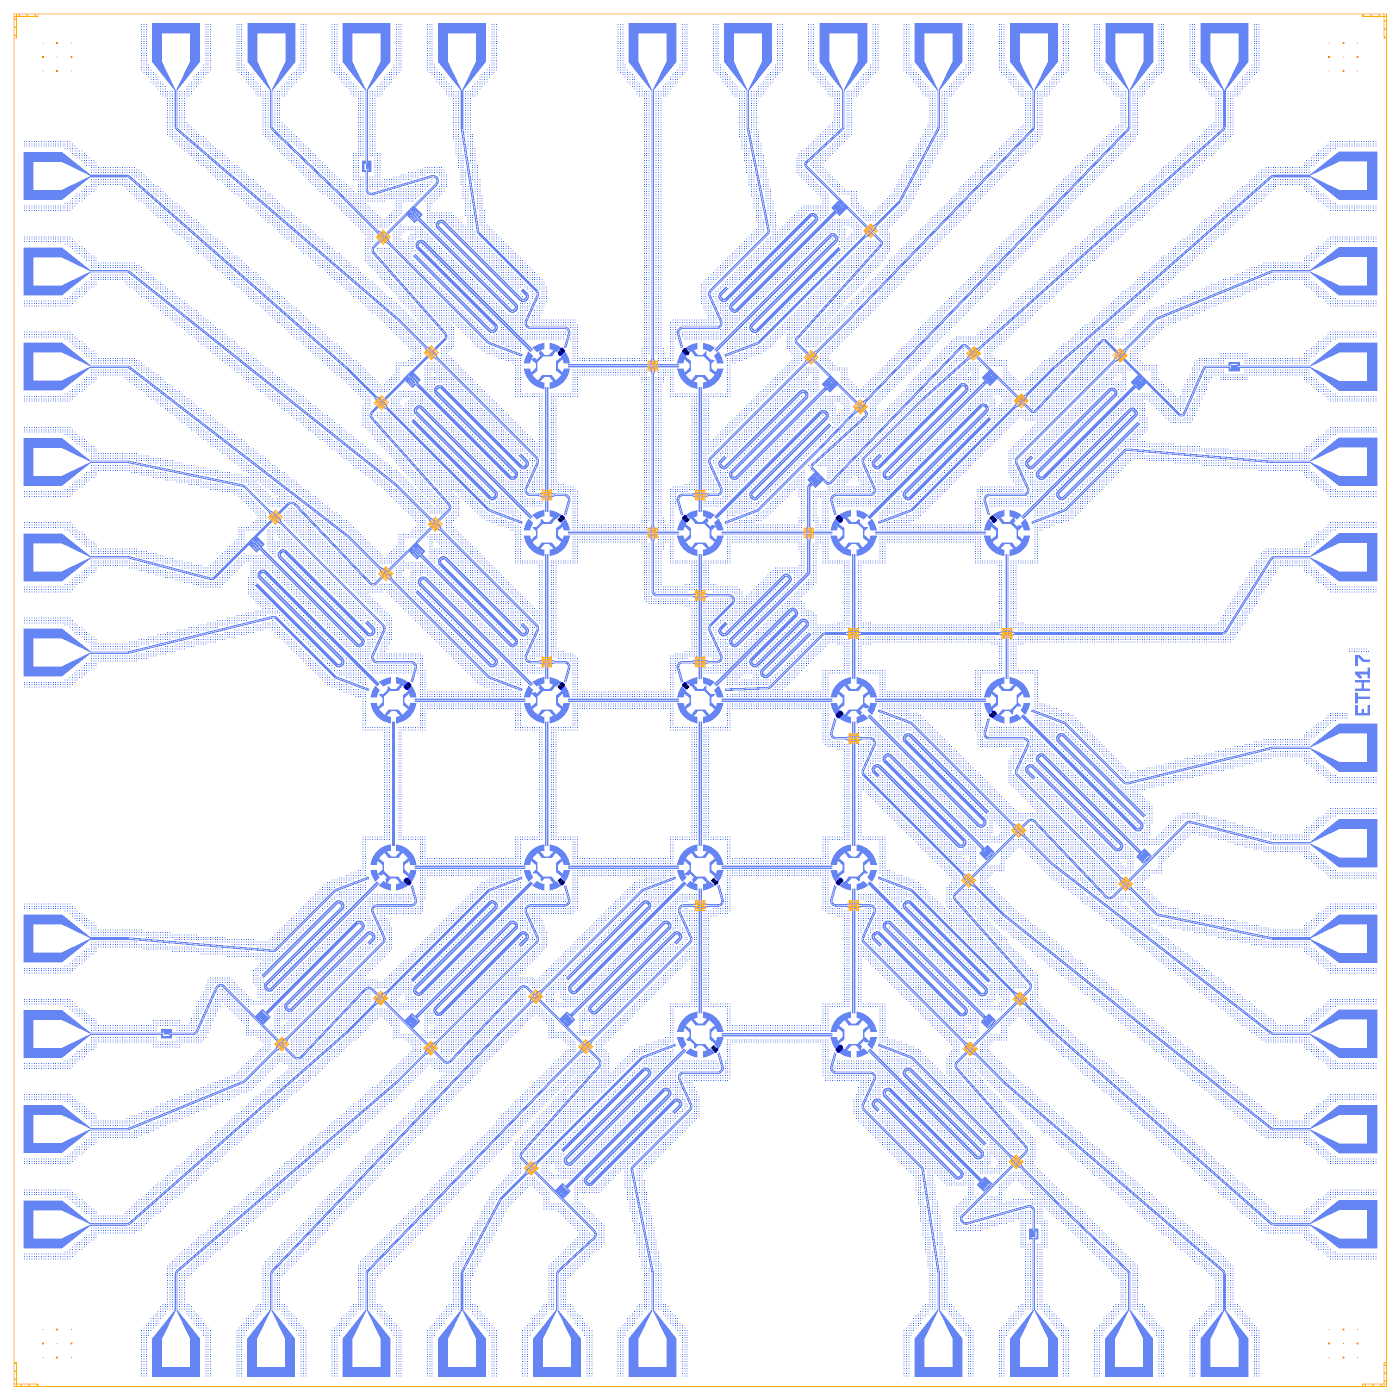

WindowsPath('examples/tutorials/img/t03_eth_chip.png')

In [21]:
rep_e = T.drc(e)
T.md(T.drc_md(rep_e, examples=1))
T.snap(e, "eth_chip", size=(1400, 1400), width=620)

**LOM against Table I.** Each qubit with its readout chain and feedline; then g (from χ: g² = χΔ(Δ + α)/α), κ_eff and
χ next to the paper. Expected: f_q within ≈ 2 %, f_r within ≈ 0.5 %, κ 3–10 MHz against 3.5–20, g and χ above the
paper (the StarQubit LOM's pad arcs: the `D5_Z3` C-matrix job calibrates them).

In [22]:
def feed_e(g):
    spec = FEEDLINES_E[g]
    return [spec["pad_in"], spec["pad_out"], f"CIN_{g}", *[r for r in e.data["routes"] if r.startswith(f"FL{g}_")],
            *[f"T_{x}" for x in spec["qubits"]]]


def chain_e(qn):
    return [qn, *[r for r in e.data["routes"] if r.startswith((f"RO_{qn}", f"PF_{qn}"))],
            *[i for i in e.data["instances"] if i.startswith((f"AB_RO_{qn}", f"AB_PF_{qn}"))]]


res_e = C.simulate_groups(e, {qn: chain_e(qn) + feed_e(QUAD_E[qn]) for qn in SITES.values()}, max_modes=3)
rows = ["| qubit | f_q LOM (paper) GHz | f_r LOM (paper) GHz | g LOM (paper) MHz | κ_r LOM (paper) MHz | "
        "χ LOM (paper) MHz |", "|---|---|---|---|---|---|"]
for qn, r in res_e.items():
    p = r.params
    fq, fr, chi, kap, a = (p.get(f"{qn}.f_q_GHz"), p.get(f"RO_{qn}.f_GHz"), p.get(f"RO_{qn}.chi_MHz"),
                           p.get(f"RO_{qn}.kappa_MHz"), p.get(f"{qn}.alpha_MHz"))
    if None in (fq, fr, chi, a, kap):
        rows.append(f"| {qn} | – | – | – | – | – |")
        continue
    dlt = (fr - fq) * 1e3
    g = (chi * dlt * (dlt + a) / a) ** 0.5 if chi * a > 0 else float("nan")
    rows.append(f"| {qn} | {fq:.3f} ({F_Q_E[qn]}) | {fr:.3f} ({F_RO_E[qn]}) | {g:.0f} ({PAPER[qn][0]}) | "
                f"{kap:.1f} ({PAPER[qn][1]}) | {chi:.2f} ({PAPER[qn][2]}) |")
T.md("\n".join(rows))

| qubit | f_q LOM (paper) GHz | f_r LOM (paper) GHz | g LOM (paper) MHz | κ_r LOM (paper) MHz | χ LOM (paper) MHz |
|---|---|---|---|---|---|
| Z1 | 6.220 (6.328) | 7.348 (7.316) | 339 (171) | 3.1 (11.2) | -13.84 (-4.7) |
| D1 | 3.803 (3.885) | 6.766 (6.769) | 351 (244) | 7.4 (6.3) | -2.54 (-2.0) |
| D4 | 3.804 (3.878) | 7.097 (7.12) | 376 (241) | 8.2 (8.7) | -2.35 (-1.6) |
| X2 | 5.856 (5.885) | 7.557 (7.554) | 321 (168) | 9.7 (20.1) | -5.75 (-1.9) |
| D2 | 3.804 (3.994) | 6.964 (6.979) | 366 (269) | 7.8 (7.2) | -2.42 (-2.2) |
| X1 | 6.006 (6.097) | 7.391 (7.372) | 324 (167) | 5.9 (15.1) | -8.72 (-2.8) |
| D7 | 3.944 (4.056) | 6.900 (6.91) | 357 (267) | 8.3 (8.6) | -2.62 (-2.3) |
| Z2 | 6.083 (6.192) | 7.514 (7.502) | 334 (170) | 6.2 (12.2) | -8.58 (-2.9) |
| D5 | 3.804 (3.895) | 7.155 (7.18) | 392 (238) | 6.6 (3.5) | -2.48 (-1.5) |
| Z3 | 5.927 (5.956) | 7.227 (7.2) | 313 (167) | 5.1 (14.3) | -9.29 (-3.2) |
| D3 | 3.804 (3.952) | 6.871 (6.88) | 359 (241) | 7.7 (8.3) | -2.48 (-1.9) |
| X4 | 6.008 (6.049) | 7.474 (7.461) | 327 (168) | 6.7 (11.0) | -7.93 (-2.6) |
| D8 | 3.804 (3.993) | 7.055 (7.075) | 373 (265) | 8.1 (8.2) | -2.38 (-2.0) |
| X3 | 5.928 (6.022) | 7.282 (7.258) | 315 (167) | 5.7 (13.0) | -8.68 (-3.2) |
| D6 | 3.657 (3.74) | 7.013 (7.032) | 372 (244) | 7.5 (9.0) | -2.25 (-1.6) |
| D9 | 3.944 (4.143) | 6.860 (6.868) | 354 (260) | 8.2 (8.9) | -2.65 (-2.4) |
| Z4 | 6.007 (6.037) | 7.428 (7.412) | 326 (171) | 6.2 (10.0) | -8.35 (-2.8) |

> **Simulation PC (32 GB+ RAM).** The cells below export the Part B jobs (`D5_readout` eigenmode with the bridged filter lead, `D5_Z3` C-matrix) for AEDT; solving them needs the simulation PC. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

**FEM jobs, export, pictures.** `D5_readout` (eigenmode, with D5's bridged filter lead — airbridge kept with
`settings={"airbridges": True}`) and `D5_Z3` (C-matrix: g between a data and an auxiliary qubit).

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| D5_Z3 | `build/jobs/t03_wallraff_17q_D5_Z3_q3d_cmatrix` | 1 · junction · `D5.junction`<br>2 · junction · `Z3.junction`<br>3 · waveguide · `D5.pin_cpl1`<br>4 · waveguide · `Z3.pin_cpl3`<br>5 · edge · `CPL_D5_X3`<br>6 · edge · `CPL_X2_D5`<br>7 · edge · `CPL_Z2_D5`<br>8 · edge · `CPL_Z3_D3`<br>9 · edge · `CPL_D2_Z3`<br>10 · edge · `XY_D5_2`<br>11 · edge · `CPL_Z3_D6`<br>12 · edge · `XY_Z3_1` | `D5.island`, `Z3.island`, `XY_D5_2`, `XY_Z3_1` |
| D5_readout | `build/jobs/t03_wallraff_17q_D5_readout_eigenmode_epr` | 1 · junction · `D5.junction`<br>2 · edge_lumped · `CPL_D1_X2`<br>3 · edge_lumped · `CPL_D5_X3`<br>4 · edge_lumped · `CPL_Z2_D5`<br>5 · edge_lumped · `FLNE_2`<br>6 · edge_lumped · `FLNE_3`<br>7 · edge_lumped · `XY_D5_2`<br>8 · edge_lumped · `XY_X2_1`<br>9 · edge_lumped · `Z_X2_1`<br>10 · edge_lumped · `CPL_D4_X2`<br>11 · edge_lumped · `Z_D5_2` | `D5.island`, `CPL_D1_X2`, `CPL_D5_X3`, `CPL_Z2_D5`, `FLNE_2`, `FLNE_3`, `XY_D5_2`, `XY_X2_1`, `Z_X2_1`, `CPL_D4_X2`, `Z_D5_2` |

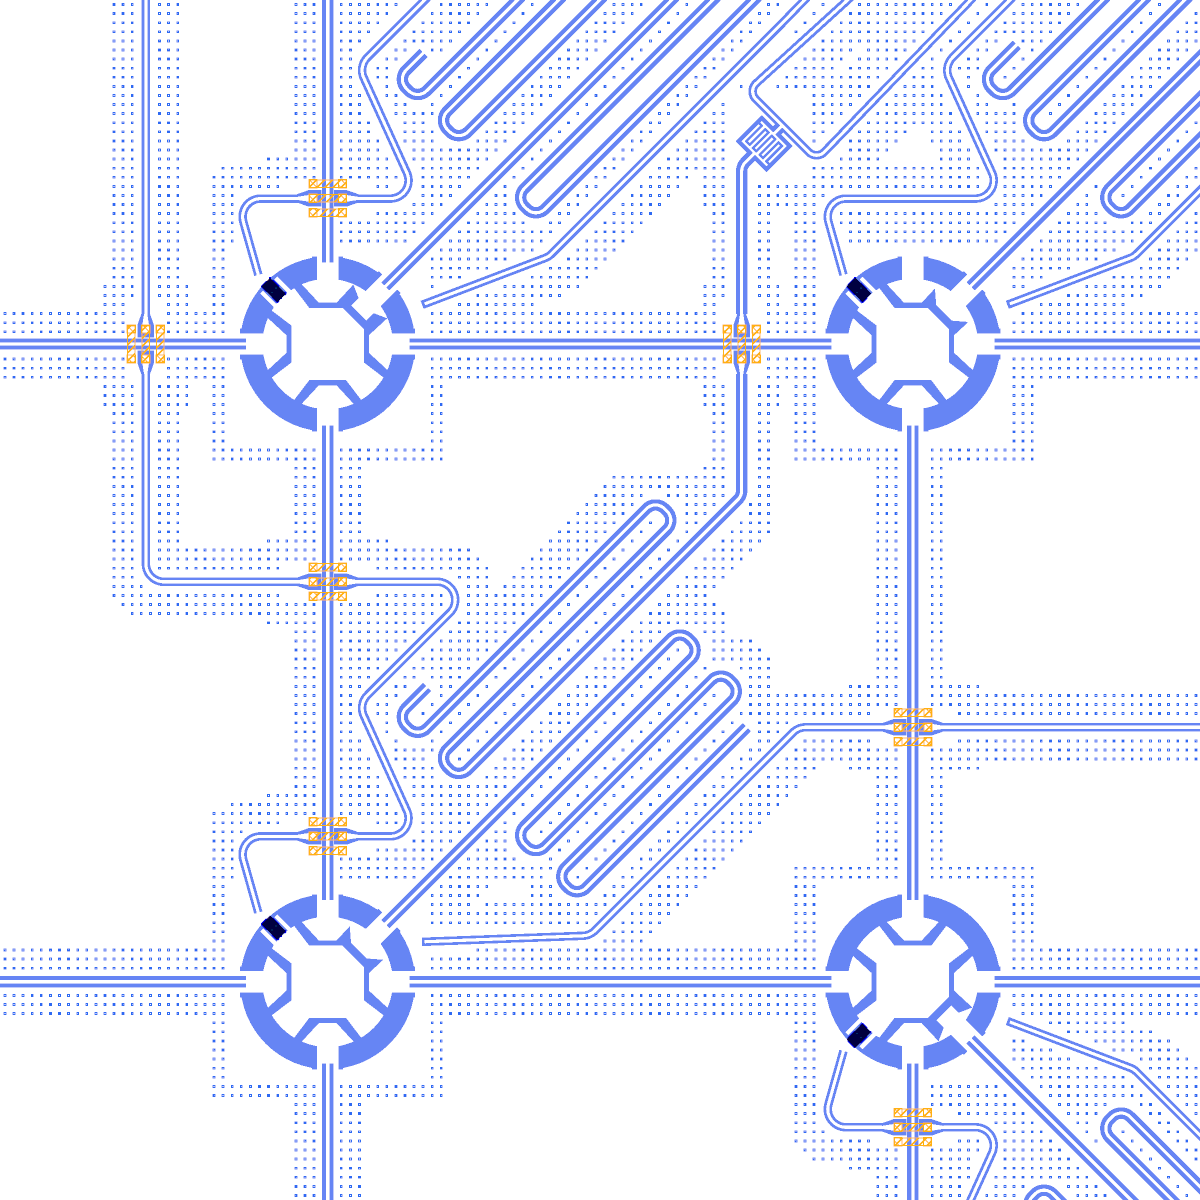

**The mock-up's own geometry** (Quantum Metal notebook 53, placed component by component in the design notebook), for comparison:

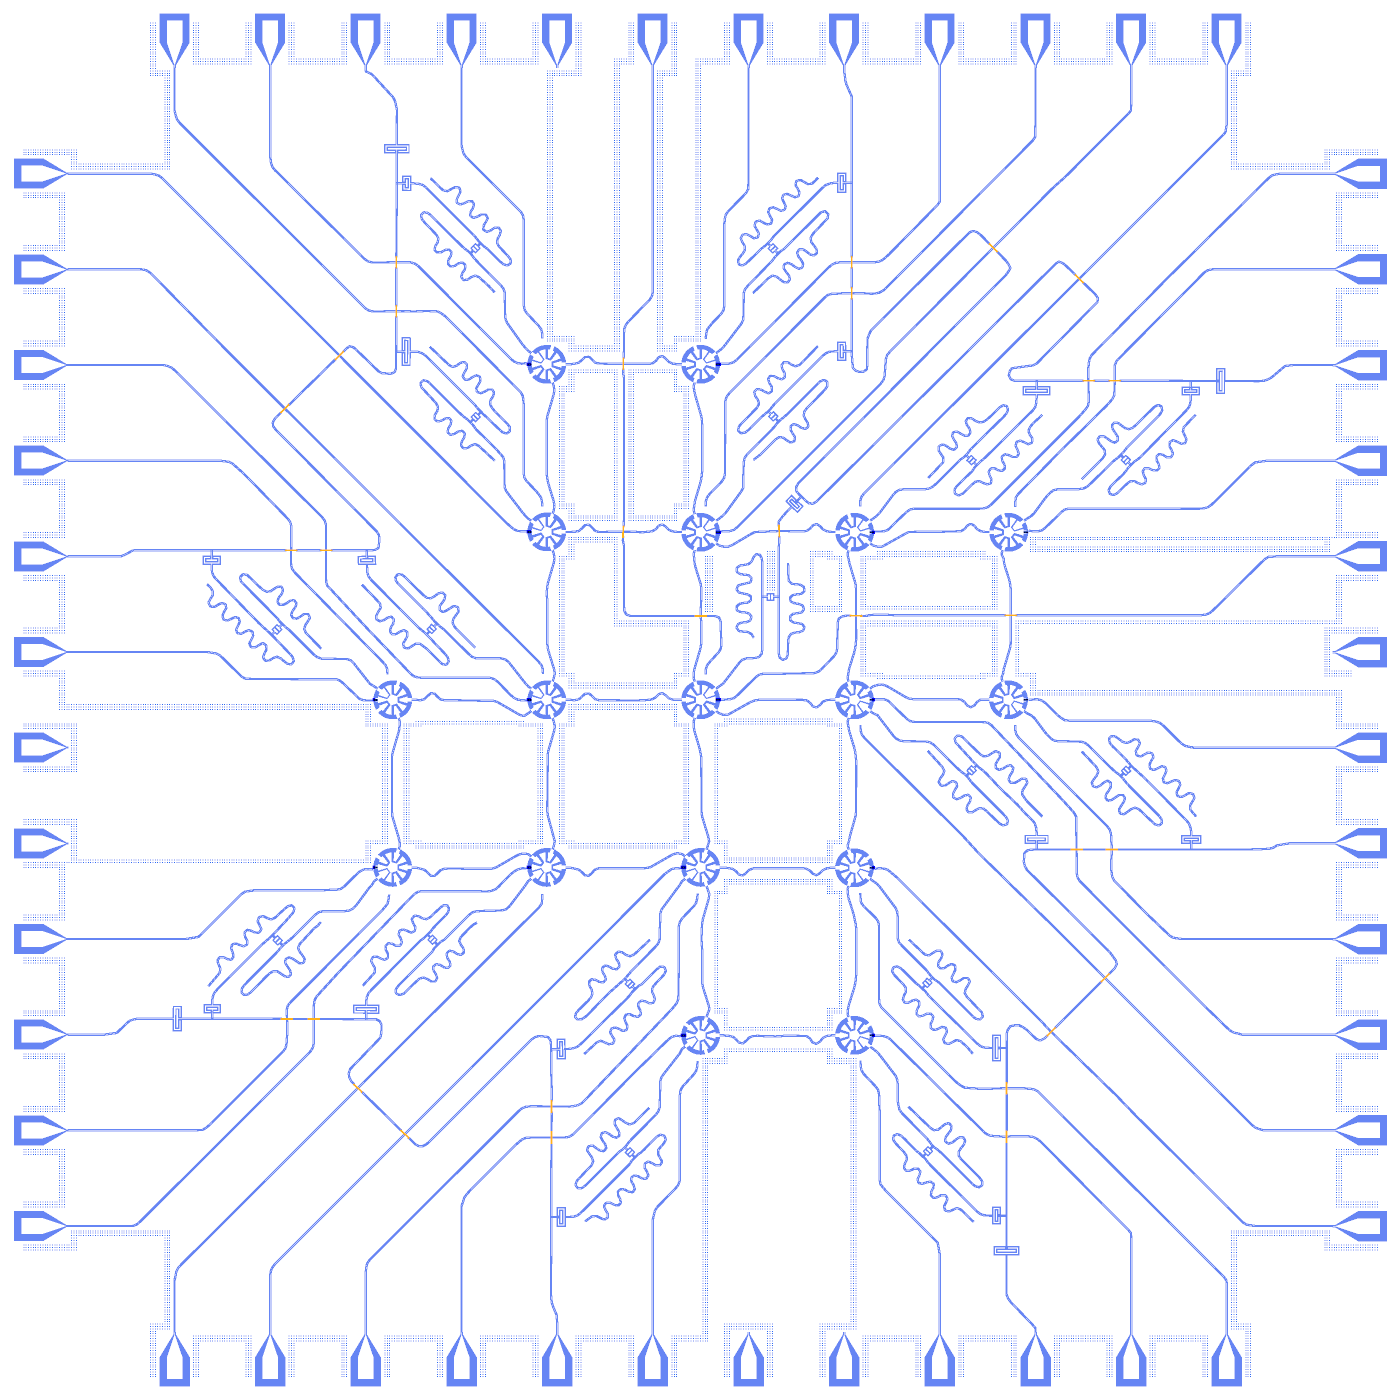

In [23]:
e.sim_group("D5_readout", ["D5", "RO_D5", "T_D5", "PF_D5", "AB_PF_D5_0", "PF_D5_1"], margin_um=150,
            analyses=["eigenmode_epr"], settings={"airbridges": True})
e.sim_group("D5_Z3", ["D5", "Z3", "CPL_D5_Z3"], margin_um=150, analyses=["q3d_cmatrix"])
DESIGN_E = e.save(T.DESIGNS / "t03_wallraff_17q.json")
jobs_e = C.export_sims(DESIGN_E, ["D5_Z3"], "q3d_cmatrix")
jobs_e_eig = C.export_sims(DESIGN_E, ["D5_readout"], "eigenmode_epr")
T.md(C.jobs_md(jobs_e) + "\n" + C.jobs_md(jobs_e_eig).split("\n", 2)[2])
T.snap(e, "eth_centre", box=(6300, 6600, 9600, 9900), size=(1200, 1200), width=520)
ref = ROOT / "docs/images/designs/metal/m53_wallraff_17q_reference.png"
if ref.exists():
    T.md("**The mock-up's own geometry** (Quantum Metal notebook 53, placed component by component in the design "
         "notebook), for comparison:")
    display(T.Image(filename=str(ref), width=520))

# Summary

| | DemoQPU17 | ETH 17q |
|---|---|---|
| **from the source** | lattice, roles, mirroring, 24 couplers, readout targets, feedline groups and order, 42-port map, CPW styles | lattice and pitch, 24 couplers, feedline groups, pad slots, Table I f_q / α / f_r |
| **ours (generator)** | diagonal hairpin readout + Purcell modules, tee taps, input capacitors, control-line fan-out, crossings → airbridges | the same, with a 180 µm StarQubit and D5's closed-plaquette module |
| **PDK** | trilayer SQUIDs; pads 100 µm from the edge; QCT frame; cheese band | the same |
| **DRC** | 0 errors; `pdk_rn` on the out-of-window junctions | 0 errors; `pdk_rn`, `pdk_fq` (data qubits below 4 GHz) |
| **LOM** | f_q, f_r, filters near target; χ larger than a real StarQubit would give | f_q / f_r near Table I; g, χ above the paper |
| **FEM** | stage 1: the `SIM_SUBSET` box (Q23, Q3D), FEM values only; stage 2: its values in the whole netlist (0 today: StarQubit pin guard), the LOM on estimates; `FEM_WHOLE` renders the whole chip (no solve); `Q23_Q33` (Q3D), `Q12_readout`, `Q33_readout` (eigenmode) exported; airbridges on/off shown | `D5_Z3` (Q3D), `D5_readout` (eigenmode, airbridges kept) exported |
| **iterate** | Q13's readout gap 8 → 15 µm: |χ| down | – |

**Simplified in both:** the readout–filter tap is declared, not drawn; no ground-plane holes or ground airbridges;
XY/Z lines are not drive/flux controls in the LOM (StarQubit has no such ports).